# Лабораторная работа №2
## Классификация. Нейронные сети

**Тема:** прогнозирование смертельного исхода у пациентов с сердечной недостаточностью (датасет *Heart Failure Clinical Records*, целевая переменная `DEATH_EVENT`).

## Введение

**Цель работы:** изучение методов классификации данных, реализованных в библиотеке Scikit-Learn, а также знакомство с нейронными сетями с использованием библиотек TensorFlow и TensorBoard.

**Задачи:**
1. Выбрать и подготовить датасет для классификации.
2. Разбить выборку на обучающую и тестовую части.
3. Построить классификаторы пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ (LDA), метод опорных векторов (SVM), метод k ближайших соседей (kNN).
4. Оценить качество по метрикам Accuracy, Precision, Recall, F1-score и AUC-ROC.
5. Настроить гиперпараметры каждого метода и исследовать их влияние на качество.
6. Построить нейронную сеть на TensorFlow/Keras, провести эксперименты с гиперпараметрами, отследить обучение в TensorBoard.
7. Сравнить все подходы и выбрать лучший для данного датасета.

**Соглашения.** Для воспроизводимости зафиксирован `RANDOM_STATE = 42`. Подбор и исследование гиперпараметров выполняются **только на обучающей выборке** (5-кратная стратифицированная кросс-валидация), тестовая выборка используется один раз — для итоговой оценки. Все масштабирования признаков вложены в `Pipeline`, поэтому они обучаются только на обучающих частях каждого фолда (нет утечки данных).

In [1]:
import os, random, shutil, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
random.seed(RANDOM_STATE); np.random.seed(RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.axisbelow": True})
pd.set_option("display.width", 160, "display.max_columns", 30)

## Выбор и подготовка датасета

### Описание датасета
Датасет *Heart Failure Clinical Records* содержит медицинские данные 299 пациентов с сердечной недостаточностью (период наблюдения от 4 до 285 дней). Задача — **бинарная классификация**: предсказать, умер ли пациент в период наблюдения (`DEATH_EVENT = 1`) или нет (`0`).

| Признак | Описание | Тип |
|---|---|---|
| `age` | возраст, лет | числовой |
| `anaemia` | снижение эритроцитов или гемоглобина | бинарный |
| `creatinine_phosphokinase` | уровень фермента КФК в крови, мкг/л | числовой |
| `diabetes` | наличие диабета | бинарный |
| `ejection_fraction` | фракция выброса, % | числовой |
| `high_blood_pressure` | гипертония | бинарный |
| `platelets` | тромбоциты, тыс./мл | числовой |
| `serum_creatinine` | креатинин сыворотки, мг/дл | числовой |
| `serum_sodium` | натрий сыворотки, мэкв/л | числовой |
| `sex` | пол (1 — мужской) | бинарный |
| `smoking` | курение | бинарный |
| `time` | срок наблюдения (follow-up), дней | числовой |
| **`DEATH_EVENT`** | **смерть в период наблюдения (целевая переменная)** | бинарный |

In [2]:
df = pd.read_csv("heart_failure_clinical_records_dataset.csv")
print("Размер таблицы:", df.shape)
display(df.head())
print("\nТипы данных и пропуски:")
display(pd.DataFrame({"dtype": df.dtypes, "пропуски": df.isna().sum(), "уникальных": df.nunique()}))
print("Полных дубликатов строк:", df.duplicated().sum())
display(df.describe().T.round(2))

Размер таблицы: (299, 13)


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1



Типы данных и пропуски:


,dtype,пропуски,уникальных
age,float64,0,47
anaemia,int64,0,2
creatinine_phosphokinase,int64,0,208
diabetes,int64,0,2
ejection_fraction,int64,0,17
high_blood_pressure,int64,0,2
platelets,float64,0,176
serum_creatinine,float64,0,40
serum_sodium,int64,0,27
sex,int64,0,2


Полных дубликатов строк: 0


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.83,11.89,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.43,0.50,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.84,970.29,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.42,0.49,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.08,11.83,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.35,0.48,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.03,97804.24,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.39,1.03,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.63,4.41,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.65,0.48,0.0,0.0,1.0,1.0,1.0


**Вывод.** В таблице 299 пациентов и 12 признаков, пропусков и дубликатов нет, все признаки числовые (бинарные уже закодированы 0/1). Целевая переменная несбалансирована: 203 выжили (67.9 %) и 96 умерли (32.1 %). Признаки сильно различаются по масштабу (например, `platelets` до 850 000, `serum_creatinine` в среднем 1.39), а `creatinine_phosphokinase` и `serum_creatinine` имеют длинные правые «хвосты» (максимумы 7861 и 9.4 при медианах 250 и 1.1) — это обосновывает стандартизацию признаков для чувствительных к масштабу методов.

DEATH_EVENT
0    203
1     96
DEATH_EVENT
0    0.679
1    0.321


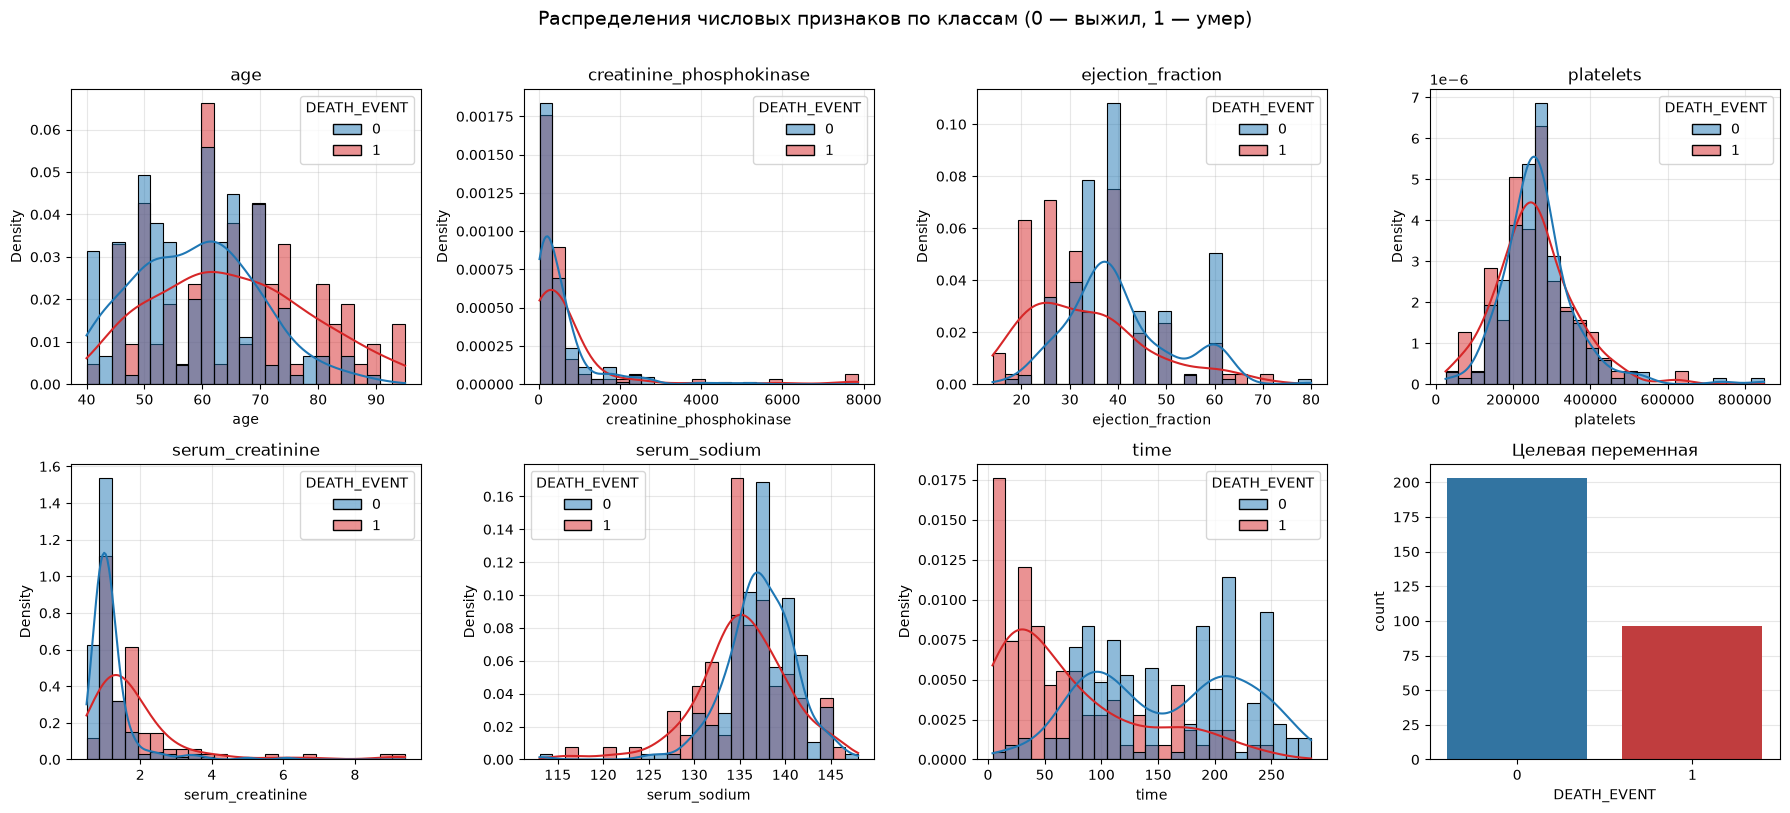

In [3]:
target = "DEATH_EVENT"
cnt = df[target].value_counts().sort_index()
print(cnt.to_string()); print((cnt / len(df)).round(3).to_string())

num_cols = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets",
            "serum_creatinine", "serum_sodium", "time"]
bin_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(data=df, x=c, hue=target, bins=25, kde=True, stat="density", common_norm=False,
                 palette={0: "tab:blue", 1: "tab:red"}, ax=ax)
    ax.set_title(c)
sns.countplot(data=df, x=target, ax=axes.ravel()[-1], palette=["tab:blue", "tab:red"])
axes.ravel()[-1].set_title("Целевая переменная")
plt.suptitle("Распределения числовых признаков по классам (0 — выжил, 1 — умер)", y=1.01, fontsize=14)
plt.tight_layout(); plt.show()

**Вывод.** Наиболее различаются по классам `time` (умершие в основном имеют короткий срок наблюдения — они выбывают из наблюдения в связи со смертью), `serum_creatinine` (у умерших смещён вправо), `ejection_fraction` (у умерших ниже), а также `age` и `serum_sodium`. `platelets` и `creatinine_phosphokinase` практически не разделяют классы.

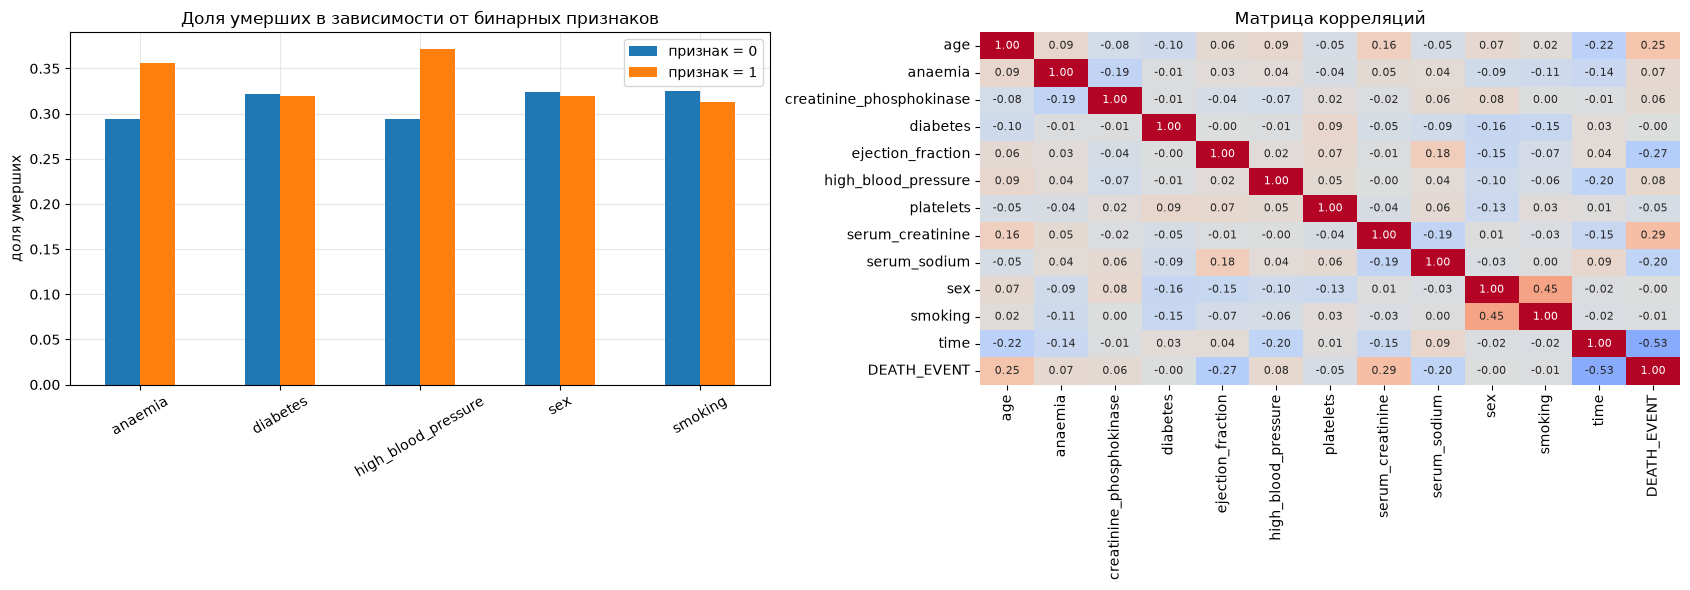

time                       -0.527
serum_creatinine            0.294
ejection_fraction          -0.269
age                         0.254
serum_sodium               -0.195
high_blood_pressure         0.079
anaemia                     0.066
creatinine_phosphokinase    0.063
platelets                  -0.049
smoking                    -0.013
sex                        -0.004
diabetes                   -0.002


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
rate = pd.DataFrame({c: df.groupby(c)[target].mean() for c in bin_cols}).T
rate.columns = ["признак = 0", "признак = 1"]
rate.plot.bar(ax=axes[0], color=["tab:blue", "tab:orange"]); axes[0].set_ylabel("доля умерших")
axes[0].set_title("Доля умерших в зависимости от бинарных признаков"); axes[0].tick_params(axis="x", rotation=30)
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1], cbar=False, annot_kws={"size": 8})
axes[1].set_title("Матрица корреляций")
plt.tight_layout(); plt.show()
print(df.corr()[target].drop(target).sort_values(key=abs, ascending=False).round(3).to_string())

**Вывод.** Самая сильная связь с целевой переменной у `time` (r = −0.53), далее `serum_creatinine` (+0.29), `ejection_fraction` (−0.27), `age` (+0.25) и `serum_sodium` (−0.20). Бинарные признаки (`diabetes`, `sex`, `smoking`) почти не влияют на исход; чуть выше смертность при анемии и гипертонии. Заметная корреляция между самими признаками есть только у `sex` и `smoking` (0.45), поэтому мультиколлинеарность не критична.

*Замечание.* `time` — срок наблюдения, который становится известен только по ходу/после наблюдения; в реальном применении такой признак при поступлении пациента недоступен. В данной работе он оставлен, как и в исходном датасете, но стоит учитывать, что именно он даёт основную часть качества моделей (см. важность признаков дерева решений ниже).

### Предобработка данных
* **Пропуски и дубликаты** отсутствуют — заполнять и удалять нечего.
* **Кодирование категорий** не требуется: все бинарные признаки уже представлены как 0/1, строковых признаков нет.
* **Масштабирование.** Признаки имеют разные порядки величин (`platelets` ~ 10⁵, `serum_creatinine` ~ 1), поэтому для методов, чувствительных к масштабу (LDA, SVM, kNN, нейросеть, GaussianNB), применяется **стандартизация** (`StandardScaler`). Для `MultinomialNB`, `ComplementNB` и `BernoulliNB` требуются неотрицательные признаки, поэтому используется **нормализация** `MinMaxScaler` в диапазон [0, 1] (с `clip=True`, чтобы значения тестовой выборки не выходили за границы). Для дерева решений масштабирование не нужно.
* **Выбросы** (`creatinine_phosphokinase`, `serum_creatinine`, `platelets`) не удаляются: это реальные клинические значения, а выборка небольшая.
* **Классы** несбалансированы (примерно 68 % / 32 %), поэтому разбиение делается со стратификацией, а помимо Accuracy обязательно учитываются Precision, Recall, F1 и AUC.
* Масштабирование встраивается в `Pipeline`, чтобы статистики (среднее, std, min, max) считались только по обучающим данным.

## Разбиение выборки
Данные делятся на обучающую (80 %) и тестовую (20 %) части функцией `train_test_split` со стратификацией по `DEATH_EVENT`.

In [5]:
X = df.drop(columns=target)
y = df[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Обучающая выборка: {X_train.shape},  тестовая выборка: {X_test.shape}")
print("Доля класса 1  — всего: %.3f, train: %.3f, test: %.3f" % (y.mean(), y_train.mean(), y_test.mean()))
print("Объектов класса 1 в тесте:", int(y_test.sum()), "из", len(y_test))

Обучающая выборка: (239, 12),  тестовая выборка: (60, 12)
Доля класса 1  — всего: 0.321, train: 0.322, test: 0.317
Объектов класса 1 в тесте: 19 из 60


**Вывод.** Получено 239 объектов для обучения и 60 для теста; доля класса «умер» сохранилась (32.2 % и 31.7 %). В тесте всего 19 положительных объектов, поэтому оценки на тесте шумные: один объект меняет Recall примерно на 5 п.п. Это учитывается ниже — решения о выборе параметров принимаются по кросс-валидации на обучающей выборке, а в конце добавлена проверка повторной кросс-валидацией.

## Вспомогательные функции
* `test_metrics` — расчёт пяти метрик на тестовой выборке (для Precision/Recall/F1 положительным классом считается `1` — смерть пациента; порог по умолчанию);
* `cv_metrics` — те же метрики, усреднённые по 5-кратной стратифицированной кросс-валидации на **обучающей** выборке;
* `sweep` / `plot_sweep` — исследование влияния одного гиперпараметра на качество (по кросс-валидации);
* `tune` — подбор гиперпараметров через `GridSearchCV` (критерий — AUC-ROC, так как он не зависит от порога и устойчив к дисбалансу классов).

In [6]:
METRICS = ["accuracy", "precision", "recall", "f1", "roc_auc"]
NAMES = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1-score", "roc_auc": "AUC-ROC"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

def std(clf):   # стандартизация + классификатор
    return Pipeline([("scaler", StandardScaler()), ("clf", clf)])
def mm(clf):    # нормализация в [0,1] + классификатор
    return Pipeline([("scaler", MinMaxScaler(clip=True)), ("clf", clf)])

def get_scores(model, X_):
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_)

def test_metrics(model, X_=None, y_=None):
    X_ = X_test if X_ is None else X_; y_ = y_test if y_ is None else y_
    pred = model.predict(X_)
    return {"accuracy": accuracy_score(y_, pred), "precision": precision_score(y_, pred, zero_division=0),
            "recall": recall_score(y_, pred), "f1": f1_score(y_, pred), "roc_auc": roc_auc_score(y_, get_scores(model, X_))}

def cv_metrics(model):
    r = cross_validate(model, X_train, y_train, cv=cv, scoring=METRICS)
    return {m: r["test_" + m].mean() for m in METRICS}

def sweep(factory, name, values):
    rows = []
    for v in values:
        d = cv_metrics(factory(v)); d[name] = v; rows.append(d)
    return pd.DataFrame(rows).set_index(name)[METRICS].rename(columns=NAMES)

def plot_sweep(df_, title, xlabel, logx=False, ax=None, metrics=None):
    show = ax is None
    if ax is None: fig, ax = plt.subplots(figsize=(7, 4.5))
    d = df_ if metrics is None else df_[[NAMES[m] for m in metrics]]
    if pd.api.types.is_numeric_dtype(df_.index):
        d.plot(ax=ax, marker="o", ms=4)
        if logx: ax.set_xscale("log")
    else:
        d.plot.bar(ax=ax, rot=0, width=0.8); ax.set_ylim(max(0, d.values.min() - 0.08), 1.0)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("значение метрики (CV)")
    if pd.api.types.is_numeric_dtype(df_.index): ax.legend(fontsize=8)
    else: ax.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.14))
    if show: plt.tight_layout(); plt.show()

def tune(name, estimator, grid, show_top=5):
    gs = GridSearchCV(estimator, grid, scoring="roc_auc", cv=cv, n_jobs=2, refit=True).fit(X_train, y_train)
    best = gs.best_estimator_
    res = test_metrics(best); res["cv_roc_auc"] = gs.best_score_
    results[name] = res; models[name] = best; best_params[name] = gs.best_params_
    print(f"[{name}] лучшие параметры: {gs.best_params_}\n  CV AUC-ROC (train): {gs.best_score_:.4f}")
    top = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").head(show_top)
    display(top[["params", "mean_test_score", "std_test_score"]].round(4).reset_index(drop=True))
    return gs

results, models, best_params = {}, {}, {}      # итоги по всем методам

## Методы классификации и настройка гиперпараметров

Для каждого метода: краткое описание → базовая модель → исследование влияния гиперпараметров (кросс-валидация на train) → подбор `GridSearchCV` → оценка на тесте.

### 1. Наивный байесовский классификатор
**Идея.** Выбирается класс с максимальной апостериорной вероятностью по формуле Байеса: $\hat y=\arg\max_c P(c)\prod_j P(x_j\mid c)$. «Наивность» — допущение условной независимости признаков при известном классе. Варианты отличаются моделью $P(x_j\mid c)$:
* **GaussianNB** — признаки нормально распределены внутри класса (параметр `var_smoothing` — добавка к дисперсиям для устойчивости);
* **MultinomialNB** — частоты/неотрицательные величины (параметр сглаживания Лапласа `alpha`);
* **ComplementNB** — вариант Multinomial для несбалансированных данных, оценивает параметры по дополнению класса (`alpha`, `norm`);
* **BernoulliNB** — бинарные признаки; числовые бинаризуются по порогу `binarize` (+ `alpha`).

Multinomial/Complement/Bernoulli применяются к признакам, нормализованным в [0, 1].

In [7]:
nb_factories = {
    "GaussianNB":    lambda **kw: std(GaussianNB(**kw)),
    "MultinomialNB": lambda **kw: mm(MultinomialNB(**kw)),
    "ComplementNB":  lambda **kw: mm(ComplementNB(**kw)),
    "BernoulliNB":   lambda **kw: mm(BernoulliNB(binarize=0.5, **kw)),   # binarize=0.5 по умолчанию для шкалы [0,1]
}
base = {}
for n, f in nb_factories.items():
    m = f().fit(X_train, y_train)
    base[n] = {**test_metrics(m), **{"CV AUC": cv_metrics(f())["roc_auc"]}}
print("Базовые модели (параметры по умолчанию), метрики на тесте:")
display(pd.DataFrame(base).T.rename(columns={**NAMES}).round(3))

Базовые модели (параметры по умолчанию), метрики на тесте:


,Accuracy,Precision,Recall,F1-score,AUC-ROC,CV AUC
GaussianNB,0.700,0.545,0.316,0.400,0.829,0.853
MultinomialNB,0.700,1.000,0.053,0.100,0.779,0.834
ComplementNB,0.683,0.500,0.474,0.486,0.779,0.834
BernoulliNB,0.750,0.750,0.316,0.444,0.809,0.764


**Вывод.** При параметрах по умолчанию все варианты хорошо ранжируют объекты (AUC 0.78–0.83), но порог 0.5 для миноритарного класса подходит плохо: Recall низкий (у `MultinomialNB` — 0.05, он почти всегда предсказывает «выжил»). Лучший Recall среди NB у `ComplementNB` (0.47) — он специально рассчитан на несбалансированные данные. `GaussianNB` лучше всех по AUC и по CV (0.853).

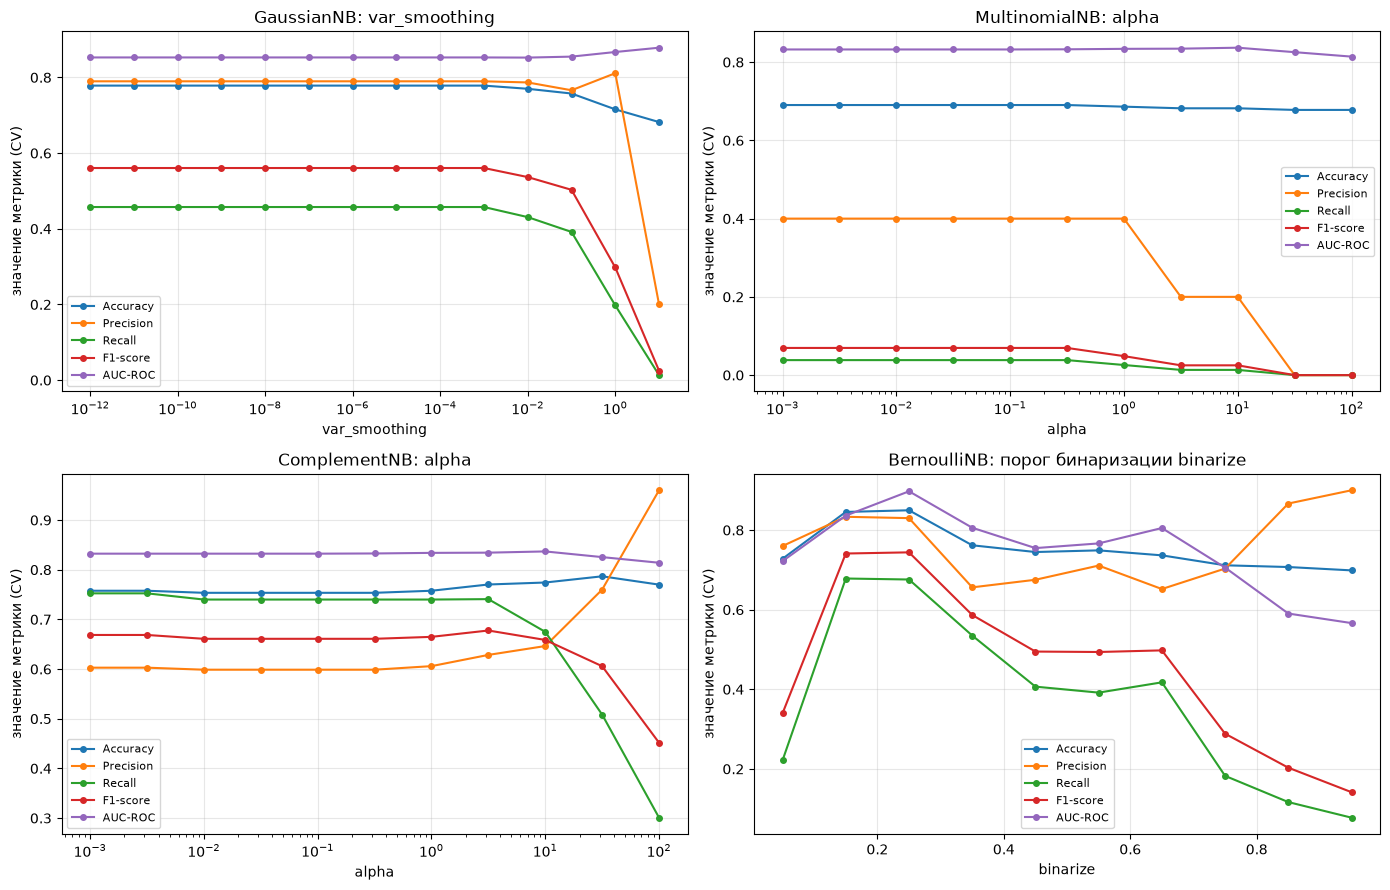

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_sweep(sweep(lambda v: std(GaussianNB(var_smoothing=v)), "var_smoothing", np.logspace(-12, 1, 14)),
           "GaussianNB: var_smoothing", "var_smoothing", True, axes[0, 0])
alphas = np.logspace(-3, 2, 11)
plot_sweep(sweep(lambda v: mm(MultinomialNB(alpha=v)), "alpha", alphas), "MultinomialNB: alpha", "alpha", True, axes[0, 1])
plot_sweep(sweep(lambda v: mm(ComplementNB(alpha=v)), "alpha", alphas), "ComplementNB: alpha", "alpha", True, axes[1, 0])
plot_sweep(sweep(lambda v: mm(BernoulliNB(binarize=v)), "binarize", np.arange(0.05, 0.96, 0.1)),
           "BernoulliNB: порог бинаризации binarize", "binarize", False, axes[1, 1])
plt.tight_layout(); plt.show()

**Влияние параметров (кросс-валидация на обучающей выборке).**
* **GaussianNB, `var_smoothing`.** До ~10⁻³ метрики не меняются (добавка пренебрежимо мала по сравнению с дисперсиями стандартизованных признаков). При росте до 0.1–1 AUC слегка растёт (до ≈0.88), но Recall и F1 резко падают: большая добавка «размывает» различия дисперсий классов, и модель предсказывает преимущественно мажоритарный класс. AUC и Recall здесь двигаются в разные стороны.
* **MultinomialNB, `alpha`.** AUC почти не зависит от `alpha` (≈0.83), а Recall не превышает 0.04 (Precision ≈ 0.4 при малых `alpha`) при любом значении: модель для этих данных (непрерывные медицинские показатели в [0, 1], не счётчики) работает плохо, при `alpha` ≥ 3 она вообще перестаёт предсказывать класс 1.
* **ComplementNB, `alpha`.** До `alpha` ≈ 3 метрики стабильны (Recall ≈ 0.74), затем Recall падает, а Precision растёт — модель становится «осторожнее».
* **BernoulliNB, порог `binarize`.** Самый чувствительный параметр: при бинаризации по 0.05 признаки почти все равны 1 (информация теряется, AUC ≈ 0.72), максимум качества достигается при 0.15–0.25 (AUC ≈ 0.90, F1 ≈ 0.74), а при порогах > 0.7 почти все признаки обнуляются и AUC падает до 0.57.

In [9]:
nb_grids = {
    "GaussianNB":    {"clf__var_smoothing": np.logspace(-12, 0, 13)},
    "MultinomialNB": {"clf__alpha": np.logspace(-3, 2, 11), "clf__fit_prior": [True, False]},
    "ComplementNB":  {"clf__alpha": np.logspace(-3, 2, 11), "clf__norm": [True, False]},
    "BernoulliNB":   {"clf__alpha": np.logspace(-3, 2, 11), "clf__binarize": np.arange(0.05, 0.96, 0.1).round(2), "clf__fit_prior": [True, False]},
}
for n, f in nb_factories.items():
    tune(n, f(), nb_grids[n], show_top=3)

[GaussianNB] лучшие параметры: {'clf__var_smoothing': np.float64(1.0)}
  CV AUC-ROC (train): 0.8672


,params,mean_test_score,std_test_score
0,{'clf__var_smoothing': 1.0},0.8672,0.0523
1,{'clf__var_smoothing': 0.1},0.8550,0.0552
2,{'clf__var_smoothing': 1e-12},0.8528,0.0553


[MultinomialNB] лучшие параметры: {'clf__alpha': np.float64(10.0), 'clf__fit_prior': True}
  CV AUC-ROC (train): 0.8369


,params,mean_test_score,std_test_score
0,"{'clf__alpha': 10.0, 'clf__fit_prior': False}",0.8369,0.0528
1,"{'clf__alpha': 10.0, 'clf__fit_prior': True}",0.8369,0.0528
2,"{'clf__alpha': 3.1622776601683795, 'clf__fit_p...",0.8344,0.0543


[ComplementNB] лучшие параметры: {'clf__alpha': np.float64(3.1622776601683795), 'clf__norm': True}
  CV AUC-ROC (train): 0.8448


,params,mean_test_score,std_test_score
0,"{'clf__alpha': 3.1622776601683795, 'clf__norm'...",0.8448,0.0529
1,"{'clf__alpha': 10.0, 'clf__norm': True}",0.8436,0.0563
2,"{'clf__alpha': 1.0, 'clf__norm': True}",0.8412,0.0567


[BernoulliNB] лучшие параметры: {'clf__alpha': np.float64(10.0), 'clf__binarize': np.float64(0.25), 'clf__fit_prior': True}
  CV AUC-ROC (train): 0.8993


,params,mean_test_score,std_test_score
0,"{'clf__alpha': 10.0, 'clf__binarize': 0.25, 'c...",0.8993,0.0308
1,"{'clf__alpha': 10.0, 'clf__binarize': 0.25, 'c...",0.8993,0.0308
2,"{'clf__alpha': 3.1622776601683795, 'clf__binar...",0.8978,0.0279


**Вывод.** По результатам `GridSearchCV` (критерий AUC): GaussianNB — `var_smoothing = 1.0` (CV AUC 0.867), MultinomialNB — `alpha = 10`, ComplementNB — `alpha ≈ 3.16, norm = True` (0.845), BernoulliNB — `alpha = 10`, `binarize = 0.25` (0.899). Подбор улучшил CV AUC у всех вариантов, но Precision/Recall при пороге 0.5 от этого не гарантированно улучшаются, так как AUC от порога не зависит (например, у ComplementNB после подбора с `norm=True` Recall на тесте упал с 0.47 до 0.21).

In [10]:
nb_names = list(nb_factories)
nb_tbl = pd.DataFrame({n: results[n] for n in nb_names}).T.rename(columns={**NAMES, "cv_roc_auc": "CV AUC (train)"})
display(nb_tbl.round(3))
best_nb = max(nb_names, key=lambda n: results[n]["cv_roc_auc"])      # выбор по кросс-валидации, а не по тесту
print("Лучший вариант наивного Байеса по CV AUC:", best_nb)

,Accuracy,Precision,Recall,F1-score,AUC-ROC,CV AUC (train)
GaussianNB,0.717,0.750,0.158,0.261,0.845,0.867
MultinomialNB,0.683,0.000,0.000,0.000,0.774,0.837
ComplementNB,0.733,0.800,0.211,0.333,0.819,0.845
BernoulliNB,0.800,0.889,0.421,0.571,0.775,0.899


Лучший вариант наивного Байеса по CV AUC: BernoulliNB


**Вывод.** По кросс-валидации лучшим вариантом наивного Байеса является **BernoulliNB** (CV AUC 0.899); на тесте он даёт и лучшую Accuracy среди NB (0.80), но его тестовый AUC (0.775) ниже, чем у GaussianNB (0.845). Расхождение CV/test обусловлено малым тестом (19 объектов класса 1) и тем, что порог бинаризации подобран на обучающих данных. Для сравнения методов далее используется BernoulliNB как представитель семейства (в итоговой таблице приведены все четыре варианта).

### 2. Дерево решений (Decision Tree)
**Идея.** Рекурсивное разбиение пространства признаков по условиям вида $x_j \le t$; в каждом узле выбирается разбиение, максимально уменьшающее неоднородность (критерий **gini** или **entropy / log_loss**). Лист возвращает класс большинства. Дерево легко интерпретируется, но склонно к переобучению, поэтому ключевые гиперпараметры — это ограничения сложности: `max_depth`, `min_samples_split`, `min_samples_leaf`, `ccp_alpha` (стоимостная обрезка).

Дерево по умолчанию (без ограничений): глубина = 8 , листьев = 30
Accuracy на train: 1.000,   на test: 0.733
CV-метрики: {'Accuracy': np.float64(0.8), 'Precision': np.float64(0.738), 'Recall': np.float64(0.625), 'F1-score': np.float64(0.667), 'AUC-ROC': np.float64(0.754)}


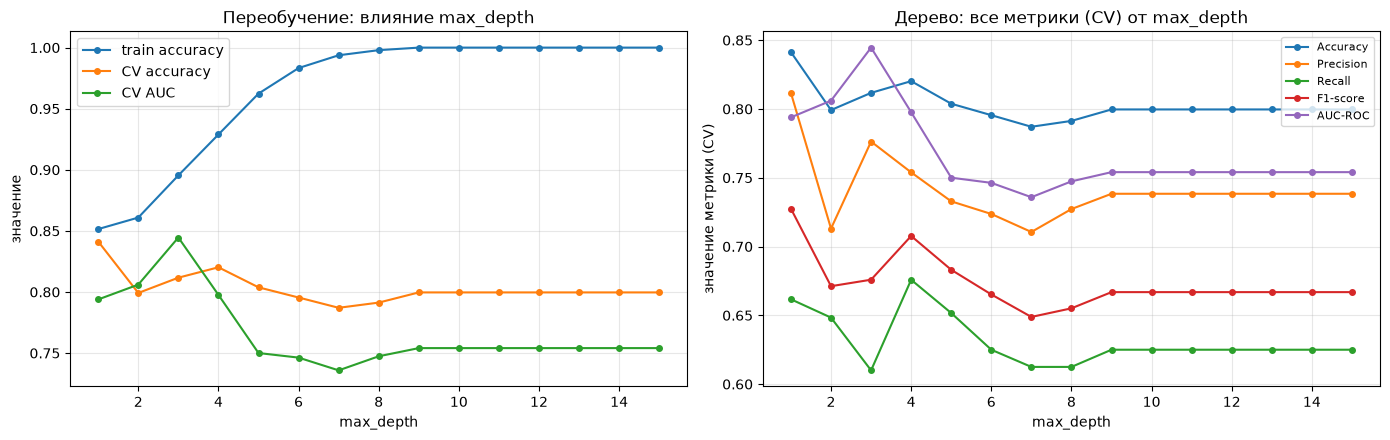

In [11]:
m = DecisionTreeClassifier(random_state=RANDOM_STATE).fit(X_train, y_train)
print("Дерево по умолчанию (без ограничений): глубина =", m.get_depth(), ", листьев =", m.get_n_leaves())
print("Accuracy на train: %.3f,   на test: %.3f" % (m.score(X_train, y_train), m.score(X_test, y_test)))
print("CV-метрики:", {NAMES[k]: round(v, 3) for k, v in cv_metrics(DecisionTreeClassifier(random_state=RANDOM_STATE)).items()})

depths = list(range(1, 16))
rows = []
for d in depths:
    mod = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    r = cross_validate(mod, X_train, y_train, cv=cv, scoring=["accuracy", "roc_auc"], return_train_score=True)
    rows.append({"max_depth": d, "train accuracy": r["train_accuracy"].mean(), "CV accuracy": r["test_accuracy"].mean(), "CV AUC": r["test_roc_auc"].mean()})
dd = pd.DataFrame(rows).set_index("max_depth")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
dd.plot(ax=axes[0], marker="o", ms=4); axes[0].set_title("Переобучение: влияние max_depth"); axes[0].set_ylabel("значение")
plot_sweep(sweep(lambda v: DecisionTreeClassifier(max_depth=v, random_state=RANDOM_STATE), "max_depth", depths),
           "Дерево: все метрики (CV) от max_depth", "max_depth", ax=axes[1])
plt.tight_layout(); plt.show()

**Вывод.** Классическая картина переобучения: дерево без ограничений (глубина 8, 30 листьев) безошибочно классифицирует обучающую выборку (accuracy 1.0), но на тесте даёт 0.733, а CV AUC всего 0.754. Точность на train растёт с глубиной до 1.0, а качество на кросс-валидации лучше всего при малой глубине: максимум AUC (≈0.845) — при `max_depth = 3`, дальше AUC падает до ≈0.74–0.75 и при глубине ≥ 9 выходит на плато (дерево уже полностью выращено). Глубина 1–4 — оптимальный диапазон для этих данных.

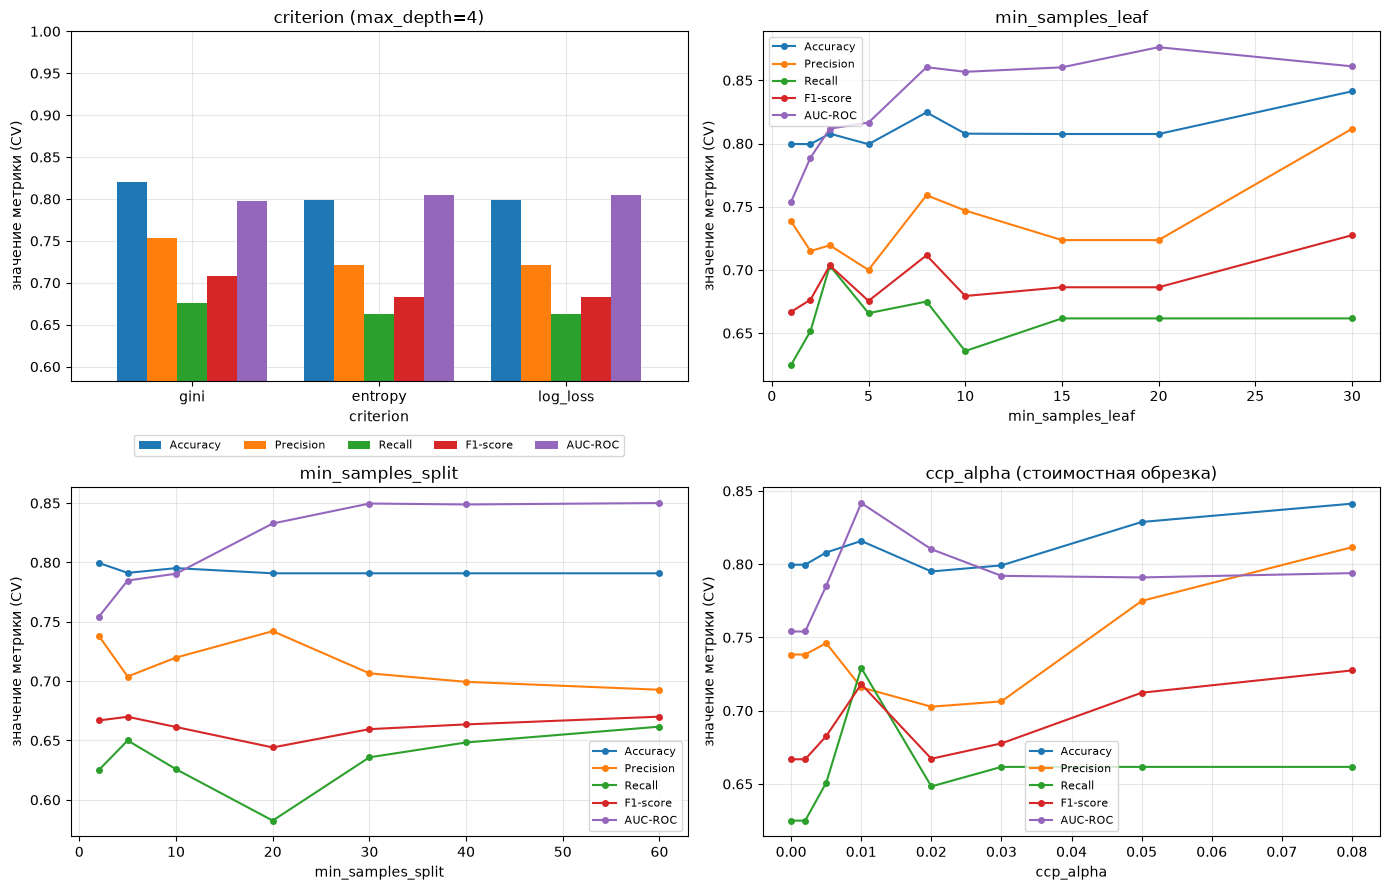

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_sweep(sweep(lambda v: DecisionTreeClassifier(criterion=v, max_depth=4, random_state=RANDOM_STATE), "criterion", ["gini", "entropy", "log_loss"]),
           "criterion (max_depth=4)", "criterion", ax=axes[0, 0])
plot_sweep(sweep(lambda v: DecisionTreeClassifier(min_samples_leaf=v, random_state=RANDOM_STATE), "min_samples_leaf", [1, 2, 3, 5, 8, 10, 15, 20, 30]),
           "min_samples_leaf", "min_samples_leaf", ax=axes[0, 1])
plot_sweep(sweep(lambda v: DecisionTreeClassifier(min_samples_split=v, random_state=RANDOM_STATE), "min_samples_split", [2, 5, 10, 20, 30, 40, 60]),
           "min_samples_split", "min_samples_split", ax=axes[1, 0])
plot_sweep(sweep(lambda v: DecisionTreeClassifier(ccp_alpha=v, random_state=RANDOM_STATE), "ccp_alpha", [0, 0.002, 0.005, 0.01, 0.02, 0.03, 0.05, 0.08]),
           "ccp_alpha (стоимостная обрезка)", "ccp_alpha", ax=axes[1, 1])
plt.tight_layout(); plt.show()

**Вывод.**
* **`criterion`:** gini, entropy и log_loss дают близкие результаты (AUC 0.80–0.81; entropy/log_loss совпадают, т.к. это одна и та же функция); влияние критерия невелико.
* **`min_samples_leaf`:** главный регуляризатор — рост значения с 1 до 8–20 поднимает CV AUC с 0.75 до 0.86–0.88, т.к. листья перестают подстраиваться под единичные объекты.
* **`min_samples_split`:** аналогично, AUC растёт с 0.75 (значение 2) до ≈0.85 при 30 и выше.
* **`ccp_alpha`:** небольшая обрезка (≈0.01) даёт максимум AUC (≈0.84) и Recall; сильная обрезка (≥ 0.03) упрощает дерево до нескольких узлов, AUC ≈ 0.79, при этом Accuracy и Precision растут, а Recall не увеличивается.

[Decision Tree] лучшие параметры: {'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 15}
  CV AUC-ROC (train): 0.8859


,params,mean_test_score,std_test_score
0,"{'ccp_alpha': 0, 'criterion': 'entropy', 'max_...",0.8859,0.0277
1,"{'ccp_alpha': 0, 'criterion': 'entropy', 'max_...",0.8859,0.0277
2,"{'ccp_alpha': 0, 'criterion': 'entropy', 'max_...",0.8859,0.0277
3,"{'ccp_alpha': 0, 'criterion': 'entropy', 'max_...",0.8859,0.0277
4,"{'ccp_alpha': 0, 'criterion': 'log_loss', 'max...",0.8859,0.0277


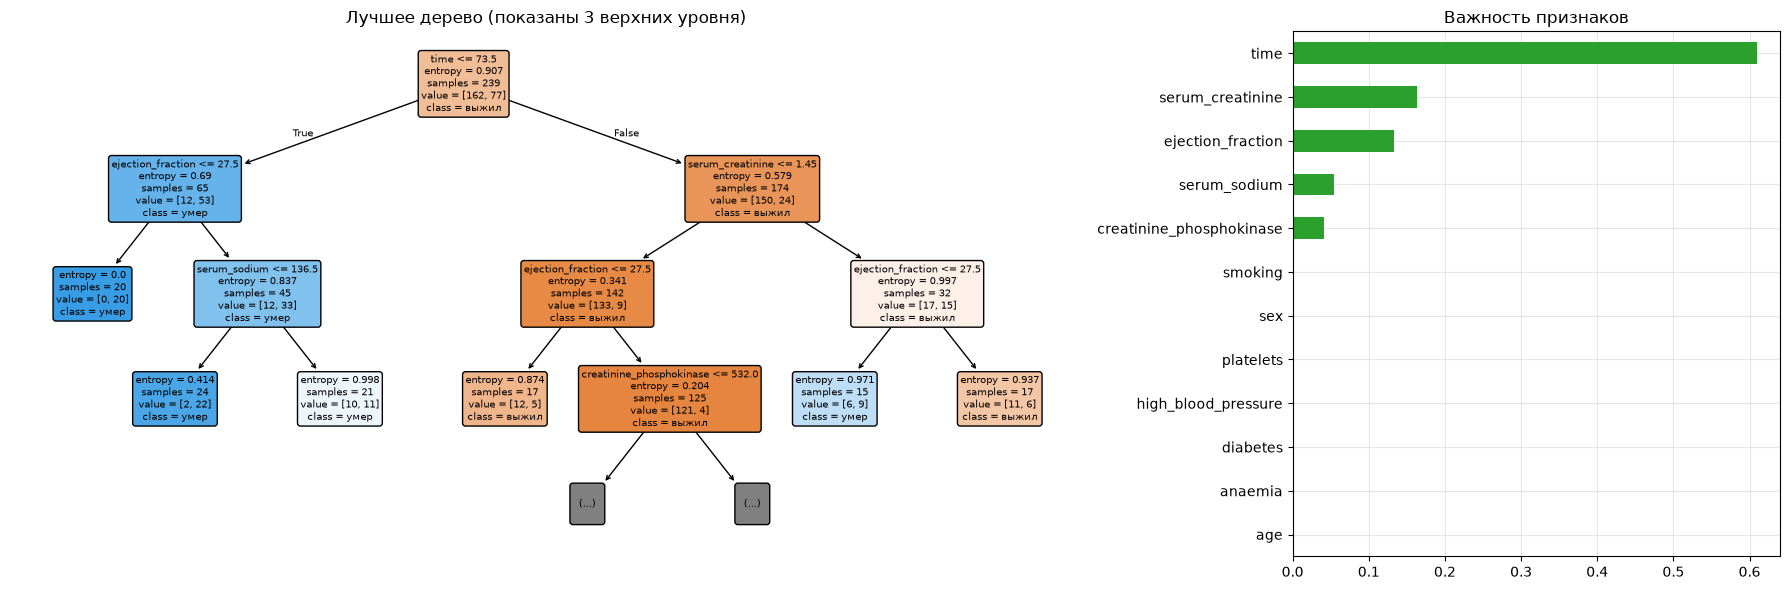

In [13]:
grid = {"criterion": ["gini", "entropy", "log_loss"], "max_depth": [2, 3, 4, 5, 6, 8, None],
        "min_samples_leaf": [1, 2, 5, 10, 15], "ccp_alpha": [0, 0.005, 0.01, 0.02]}
gs_dt = tune("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE), grid)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={"width_ratios": [2.2, 1]})
plot_tree(models["Decision Tree"], feature_names=X.columns, class_names=["выжил", "умер"], filled=True, rounded=True, max_depth=3, fontsize=7, ax=axes[0])
axes[0].set_title("Лучшее дерево (показаны 3 верхних уровня)"); axes[0].grid(False)
imp = pd.Series(models["Decision Tree"].feature_importances_, index=X.columns).sort_values()
imp.plot.barh(ax=axes[1], color="tab:green"); axes[1].set_title("Важность признаков")
plt.tight_layout(); plt.show()

**Вывод.** Лучшее дерево: `criterion = entropy`, `max_depth = 5`, `min_samples_leaf = 15` (CV AUC 0.886 против 0.754 у дерева по умолчанию). На тесте: Accuracy 0.833, Precision 0.909, Recall 0.526, F1 0.667, AUC 0.852 — подбор параметров существенно улучшил модель (Accuracy с 0.733 до 0.833). Дерево легко интерпретируется: корневое условие — `time ≤ 73.5` (малый срок наблюдения → высокая доля умерших), далее `ejection_fraction ≤ 27.5` и `serum_creatinine ≤ 1.45`. По важности признаков доминируют `time` (≈0.61), `serum_creatinine` (≈0.16) и `ejection_fraction` (≈0.13), что согласуется с корреляционным анализом.

### 3. Линейный дискриминантный анализ (LDA)
**Идея.** Предполагается, что в каждом классе признаки распределены нормально с **общей** ковариационной матрицей $\Sigma$. Тогда граница между классами линейна: $\delta_c(x)=x^T\Sigma^{-1}\mu_c-\tfrac12\mu_c^T\Sigma^{-1}\mu_c+\ln\pi_c$. LDA одновременно проецирует данные на ось, максимально разделяющую классы (для двух классов размерность проекции — 1). Гиперпараметры: способ решения `solver` (`svd`, `lsqr`, `eigen`), **усадка ковариационной матрицы** `shrinkage` (`lsqr`/`eigen`; устойчивость при коррелированных признаках и малой выборке), априорные вероятности классов `priors`, `tol`.

LDA по умолчанию, тест: {'Accuracy': 0.817, 'Precision': 0.786, 'Recall': 0.579, 'F1-score': 0.667, 'AUC-ROC': 0.854}


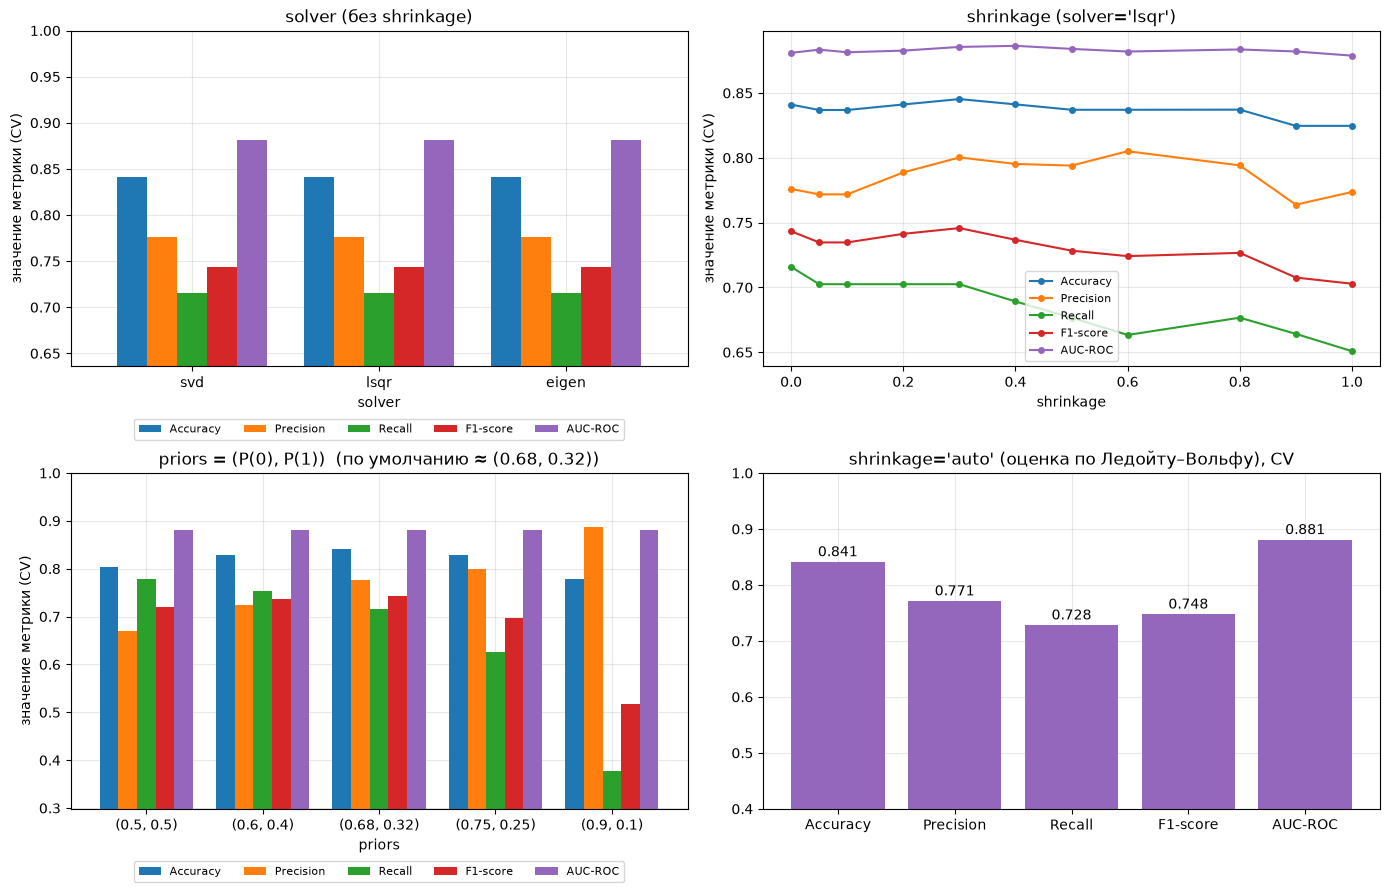

In [14]:
base_lda = std(LinearDiscriminantAnalysis()).fit(X_train, y_train)
print("LDA по умолчанию, тест:", {NAMES[k]: round(v, 3) for k, v in test_metrics(base_lda).items()})

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plot_sweep(sweep(lambda v: std(LinearDiscriminantAnalysis(solver=v)), "solver", ["svd", "lsqr", "eigen"]),
           "solver (без shrinkage)", "solver", ax=axes[0, 0])
plot_sweep(sweep(lambda v: std(LinearDiscriminantAnalysis(solver="lsqr", shrinkage=v)), "shrinkage", [0, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.8, 0.9, 1.0]),
           "shrinkage (solver='lsqr')", "shrinkage", ax=axes[0, 1])
plot_sweep(sweep(lambda v: std(LinearDiscriminantAnalysis(priors=v)), "priors",
                 [(0.5, 0.5), (0.6, 0.4), (0.68, 0.32), (0.75, 0.25), (0.9, 0.1)]).rename(index=str),
           "priors = (P(0), P(1))  (по умолчанию ≈ (0.68, 0.32))", "priors", ax=axes[1, 0])
s_auto = cv_metrics(std(LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto")))
axes[1, 1].bar([NAMES[k] for k in s_auto], list(s_auto.values()), color="tab:purple"); axes[1, 1].set_ylim(0.4, 1)
axes[1, 1].set_title("shrinkage='auto' (оценка по Ледойту–Вольфу), CV")
for i, v in enumerate(s_auto.values()): axes[1, 1].text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout(); plt.show()

**Вывод.**
* **`solver`:** `svd`, `lsqr`, `eigen` дают одинаковые результаты (AUC ≈ 0.88) — все они решают одну и ту же задачу, различаются вычислительно (`svd` не вычисляет ковариационную матрицу и устойчивее при большом числе признаков, `lsqr` — быстрее и поддерживает shrinkage).
* **`shrinkage`:** влияние слабое: AUC держится в диапазоне 0.88–0.886 с небольшим максимумом около 0.3; при сильной усадке (→ 1, ковариация приближается к диагональной) Recall снижается (0.72 → 0.65). Автоматический выбор (`auto`, метод Ледойта–Вольфа) даёт AUC 0.881 — практически то же. Малая чувствительность объясняется тем, что признаков мало (12) относительно объектов (239), и оценка ковариационной матрицы и без усадки устойчива.
* **`priors`:** AUC не меняется (0.88), но меняется баланс Precision/Recall: при равных априорных (0.5, 0.5) Recall максимален (≈0.78) за счёт Precision (≈0.67); при (0.9, 0.1) модель почти не предсказывает класс 1 (Recall ≈ 0.38). Это простой способ сместить порог решения в пользу миноритарного класса, что важно, если ошибка пропуска опаснее ложной тревоги.

[LDA] лучшие параметры: {'clf__shrinkage': 0.3, 'clf__solver': 'lsqr'}
  CV AUC-ROC (train): 0.8855


,params,mean_test_score,std_test_score
0,"{'clf__shrinkage': 0.3, 'clf__solver': 'lsqr'}",0.8855,0.0303
1,"{'clf__shrinkage': 0.3, 'clf__solver': 'eigen'}",0.8855,0.0303
2,"{'clf__shrinkage': 0.5, 'clf__solver': 'lsqr'}",0.8840,0.0362
3,"{'clf__shrinkage': 0.5, 'clf__solver': 'eigen'}",0.8840,0.0362
4,"{'clf__shrinkage': 0.05, 'clf__solver': 'eigen'}",0.8834,0.0288


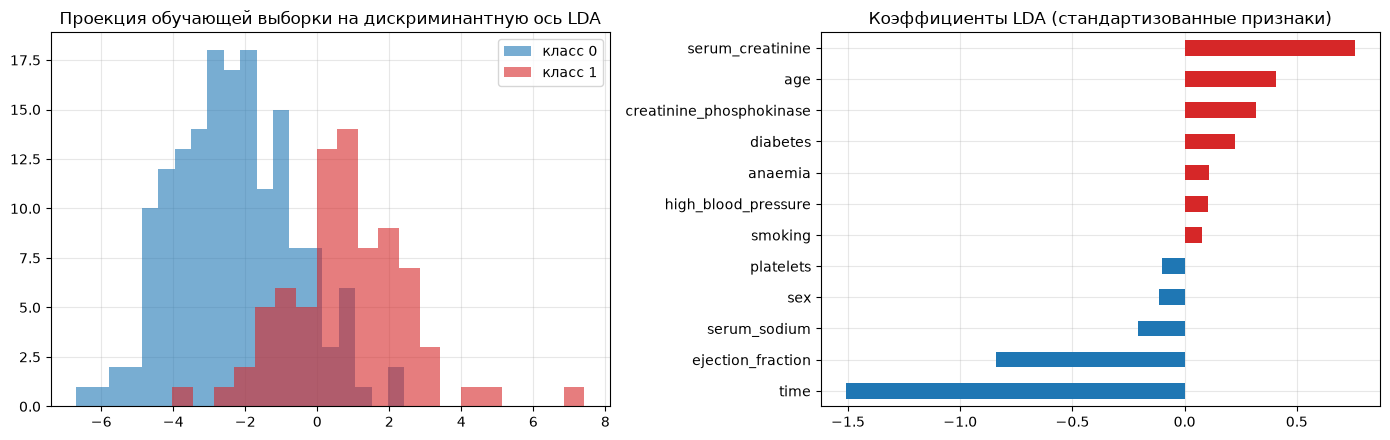

In [15]:
grid = [{"clf__solver": ["svd"], "clf__tol": [1e-4, 1e-3, 1e-2]},
        {"clf__solver": ["lsqr", "eigen"], "clf__shrinkage": [None, "auto", 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9]}]
gs_lda = tune("LDA", std(LinearDiscriminantAnalysis()), grid)

lda = models["LDA"]
proj_tr = pd.Series(lda.decision_function(X_train), index=X_train.index)   # положение объекта на дискриминантной оси
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for c, col in [(0, "tab:blue"), (1, "tab:red")]:
    axes[0].hist(proj_tr[y_train == c], bins=20, alpha=.6, color=col, label=f"класс {c}")
axes[0].set_title("Проекция обучающей выборки на дискриминантную ось LDA"); axes[0].legend()
coef = pd.Series(lda.named_steps["clf"].coef_.ravel(), index=X.columns).sort_values()
coef.plot.barh(ax=axes[1], color=["tab:blue" if v < 0 else "tab:red" for v in coef]); axes[1].set_title("Коэффициенты LDA (стандартизованные признаки)")
plt.tight_layout(); plt.show()

**Вывод.** Лучшие параметры по CV: `solver = lsqr`, `shrinkage = 0.3` (CV AUC 0.886; значения у соседних вариантов практически совпадают). На тесте: Accuracy 0.800, Precision 0.769, Recall 0.526, F1 0.625, AUC 0.865 (у LDA по умолчанию: Accuracy 0.817, AUC 0.854) — различия в пределах шума. Проекция на дискриминантную ось хорошо разделяет классы, а знаки коэффициентов согласуются с медициной: риск растёт с возрастом и креатинином и падает с ростом срока наблюдения `time` и фракции выброса.

### 4. Метод опорных векторов (SVM)
**Идея.** Строится разделяющая гиперплоскость с максимальным зазором (margin) между классами; на границе лежат опорные векторы. Нелинейность достигается заменой скалярного произведения **ядром** (kernel trick). Гиперпараметры:
* `kernel` — `linear`, `poly`, `rbf`, `sigmoid`;
* `C` — штраф за ошибки (малое $C$ → широкий зазор и больше ошибок, большое $C$ → риск переобучения);
* `gamma` — ширина ядра `rbf/poly/sigmoid` (большое значение → «локальная» модель);
* `degree` — степень полиномиального ядра; `class_weight` — веса классов.

AUC-ROC вычисляется по решающей функции `decision_function`.

SVM по умолчанию (rbf, C=1, gamma='scale'), тест: {'Accuracy': 0.767, 'Precision': 0.727, 'Recall': 0.421, 'F1-score': 0.533, 'AUC-ROC': 0.845}


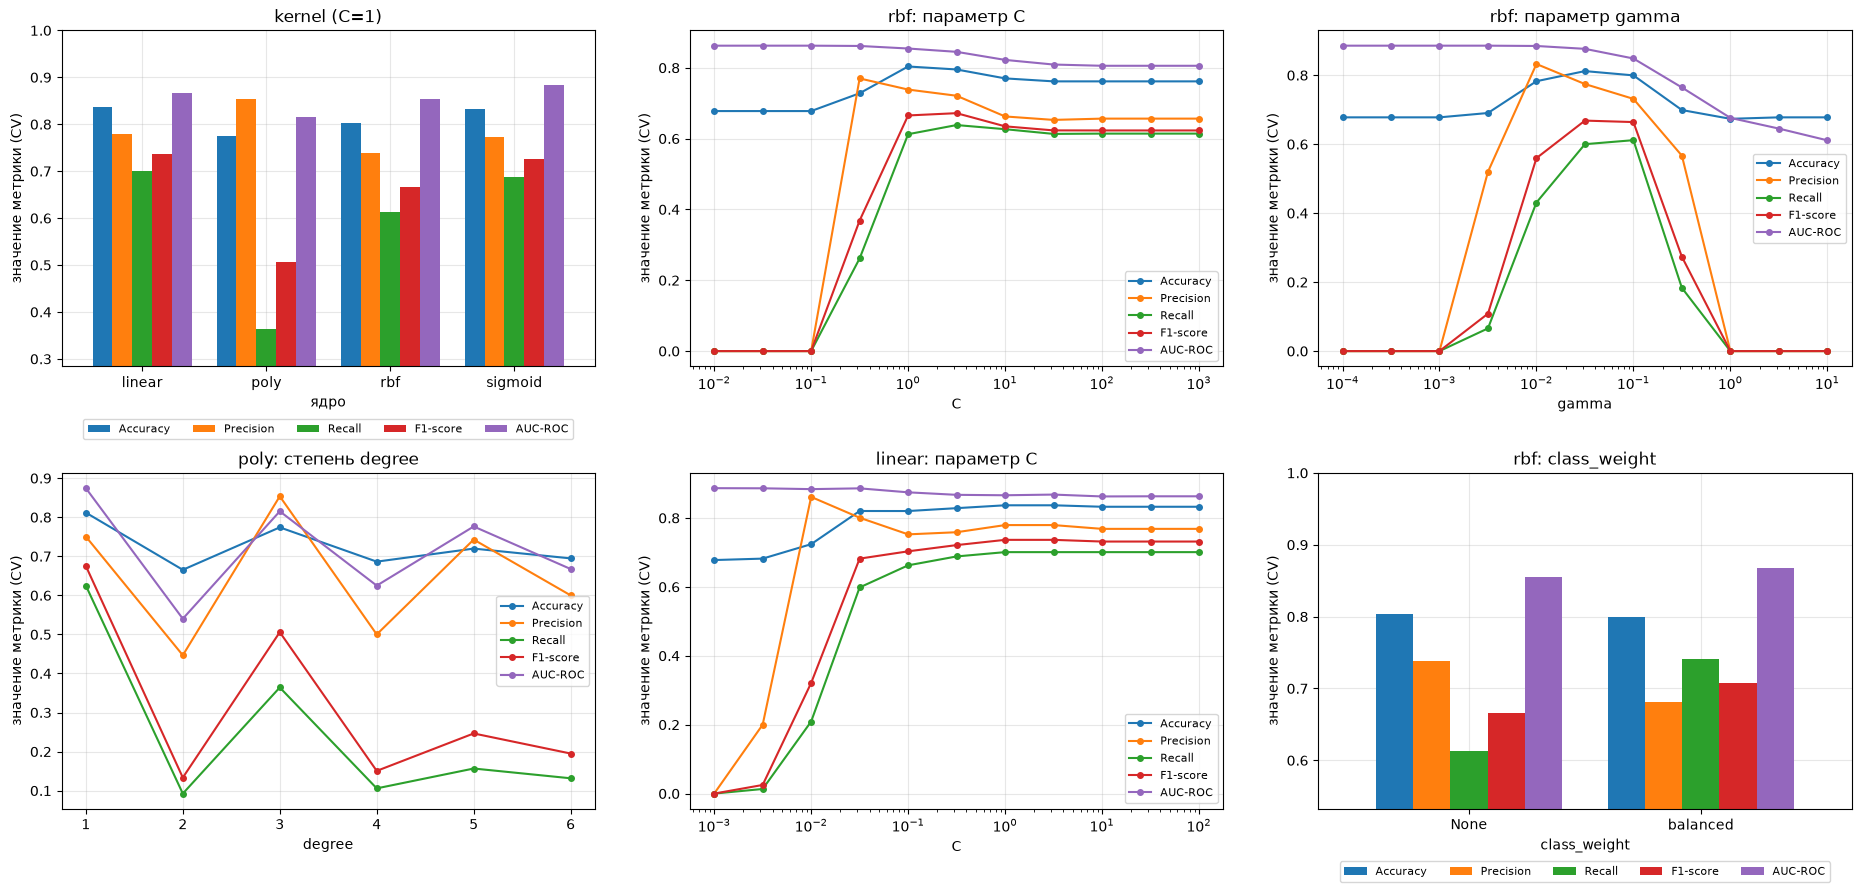

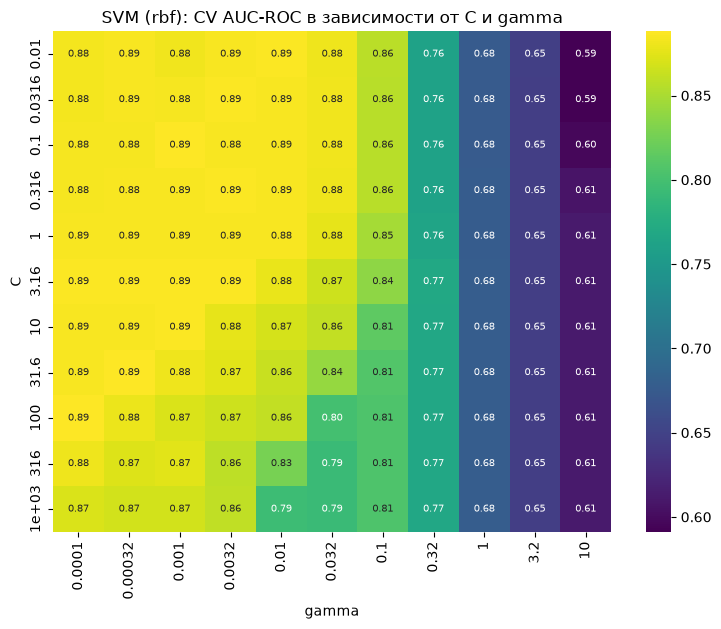

In [16]:
base_svm = std(SVC()).fit(X_train, y_train)
print("SVM по умолчанию (rbf, C=1, gamma='scale'), тест:", {NAMES[k]: round(v, 3) for k, v in test_metrics(base_svm).items()})

fig, axes = plt.subplots(2, 3, figsize=(19, 9))
plot_sweep(sweep(lambda v: std(SVC(kernel=v)), "kernel", ["linear", "poly", "rbf", "sigmoid"]), "kernel (C=1)", "ядро", ax=axes[0, 0])
plot_sweep(sweep(lambda v: std(SVC(kernel="rbf", C=v)), "C", np.logspace(-2, 3, 11)), "rbf: параметр C", "C", True, axes[0, 1])
plot_sweep(sweep(lambda v: std(SVC(kernel="rbf", gamma=v)), "gamma", np.logspace(-4, 1, 11)), "rbf: параметр gamma", "gamma", True, axes[0, 2])
plot_sweep(sweep(lambda v: std(SVC(kernel="poly", degree=v)), "degree", [1, 2, 3, 4, 5, 6]), "poly: степень degree", "degree", False, axes[1, 0])
plot_sweep(sweep(lambda v: std(SVC(kernel="linear", C=v)), "C", np.logspace(-3, 2, 11)), "linear: параметр C", "C", True, axes[1, 1])
plot_sweep(sweep(lambda v: std(SVC(class_weight=None if v == "None" else v)), "class_weight", ["None", "balanced"]), "rbf: class_weight", "class_weight", ax=axes[1, 2])
plt.tight_layout(); plt.show()

# двумерное исследование C × gamma (AUC-ROC по CV)
Cs, gs_ = np.logspace(-2, 3, 11), np.logspace(-4, 1, 11)
H = np.array([[cv_metrics(std(SVC(C=c, gamma=g)))["roc_auc"] for g in gs_] for c in Cs])
plt.figure(figsize=(9, 6.5))
sns.heatmap(pd.DataFrame(H, index=[f"{c:.3g}" for c in Cs], columns=[f"{g:.2g}" for g in gs_]), annot=True, fmt=".2f", cmap="viridis", annot_kws={"size": 7})
plt.xlabel("gamma"); plt.ylabel("C"); plt.title("SVM (rbf): CV AUC-ROC в зависимости от C и gamma"); plt.grid(False); plt.show()

**Вывод.**
* **Ядро (C = 1):** лучшие результаты у `linear` (AUC ≈ 0.865, Recall ≈ 0.70) и `rbf`/`sigmoid`; `poly` (степень 3) заметно хуже (Recall ≈ 0.37, AUC ≈ 0.82) — данные близки к линейно разделимым, сложные ядра не дают выигрыша.
* **`C` (rbf):** при `C` < 0.3 штраф слишком мал, зазор огромен и модель предсказывает только мажоритарный класс (Precision = Recall = 0 при AUC всё ещё ≈ 0.86, т.к. ранжирование сохраняется). Accuracy максимальна при `C` ≈ 1 (≈ 0.80); при росте `C` до 10³ качество плавно ухудшается (AUC 0.86 → 0.81) из-за переобучения.
* **`gamma` (rbf):** при очень малых значениях (≤ 10⁻³) ядро почти константное, модель «вырождается» в мажоритарный класс; оптимум Accuracy/F1 — `gamma` ≈ 0.01–0.1; при `gamma` ≥ 1 ядро становится слишком локальным: SVM запоминает обучающие точки, Precision/Recall → 0, AUC падает до 0.61–0.68.
* **`degree` (poly):** лучшее качество — при `degree = 1` (линейная граница); для чётных степеней качество резко ухудшается (AUC до 0.54 при `degree = 2`).
* **`C` (linear):** при `C` < 0.03 модель вырождается, при `C` ≥ 0.1 — плато (AUC ≈ 0.87–0.89); линейное ядро нечувствительно к большим `C`.
* **`class_weight='balanced'`:** Recall вырос с 0.61 до 0.74 (Precision снизился с 0.74 до 0.68), AUC — 0.855 → 0.868; полезный приём при дисбалансе классов.
* **Тепловая карта C × gamma:** «зона хорошего качества» (AUC ≈ 0.86–0.89) находится при малых `gamma` (≤ 0.003) практически для любого `C` и при небольших `C` с `gamma` до 0.03; верхний правый угол (большие `gamma`) — переобучение.

In [17]:
grid = [{"clf__kernel": ["linear"], "clf__C": np.logspace(-3, 2, 11)},
        {"clf__kernel": ["rbf"], "clf__C": np.logspace(-2, 3, 11), "clf__gamma": ["scale"] + list(np.logspace(-4, 0, 9))},
        {"clf__kernel": ["poly"], "clf__C": [0.1, 1, 10], "clf__degree": [2, 3, 4], "clf__gamma": ["scale", 0.01, 0.1]},
        {"clf__kernel": ["sigmoid"], "clf__C": [0.1, 1, 10], "clf__gamma": ["scale", 0.001, 0.01]}]
gs_svm = tune("SVM", std(SVC()), grid)

[SVM] лучшие параметры: {'clf__C': np.float64(100.0), 'clf__gamma': np.float64(0.0001), 'clf__kernel': 'rbf'}
  CV AUC-ROC (train): 0.8881


,params,mean_test_score,std_test_score
0,"{'clf__C': 100.0, 'clf__gamma': 0.0001, 'clf__...",0.8881,0.0335
1,"{'clf__C': 0.1, 'clf__gamma': 0.001, 'clf__ker...",0.8881,0.0376
2,"{'clf__C': 0.1, 'clf__gamma': 'scale', 'clf__k...",0.8880,0.0381
3,"{'clf__C': 31.622776601683793, 'clf__gamma': 0...",0.8877,0.0343
4,"{'clf__C': 0.1, 'clf__gamma': 0.01, 'clf__kern...",0.8873,0.0361


**Вывод.** Лучшая найденная комбинация — rbf, `C = 100`, `gamma = 10⁻⁴` (CV AUC 0.888); следующие по рангу почти не отличаются (`C = 0.1, gamma = 0.001`: 0.888), т.е. имеется плоское «плато» решений, близких к линейному классификатору. На тесте: Accuracy 0.817, Precision 0.900, Recall 0.474, F1 0.621, **AUC 0.868 — лучший AUC среди всех методов на тесте**. При параметрах по умолчанию тестовый AUC был 0.845.

### 5. Метод k ближайших соседей (kNN)
**Идея.** Объект относится к классу, преобладающему среди его $k$ ближайших объектов обучающей выборки. Модель «ленивая»: обучения нет, все вычисления — при предсказании. Гиперпараметры: число соседей `n_neighbors` (малое $k$ → высокая дисперсия/переобучение, большое → сглаживание и недообучение), схема весов `weights` (`uniform`, `distance`), метрика расстояния `metric` и степень `p` метрики Минковского (p=1 — манхэттенская, p=2 — евклидова). Метод крайне чувствителен к масштабу признаков, что будет показано экспериментом.

kNN по умолчанию (k=5), тест: {'Accuracy': 0.7, 'Precision': 0.571, 'Recall': 0.211, 'F1-score': 0.308, 'AUC-ROC': 0.8}


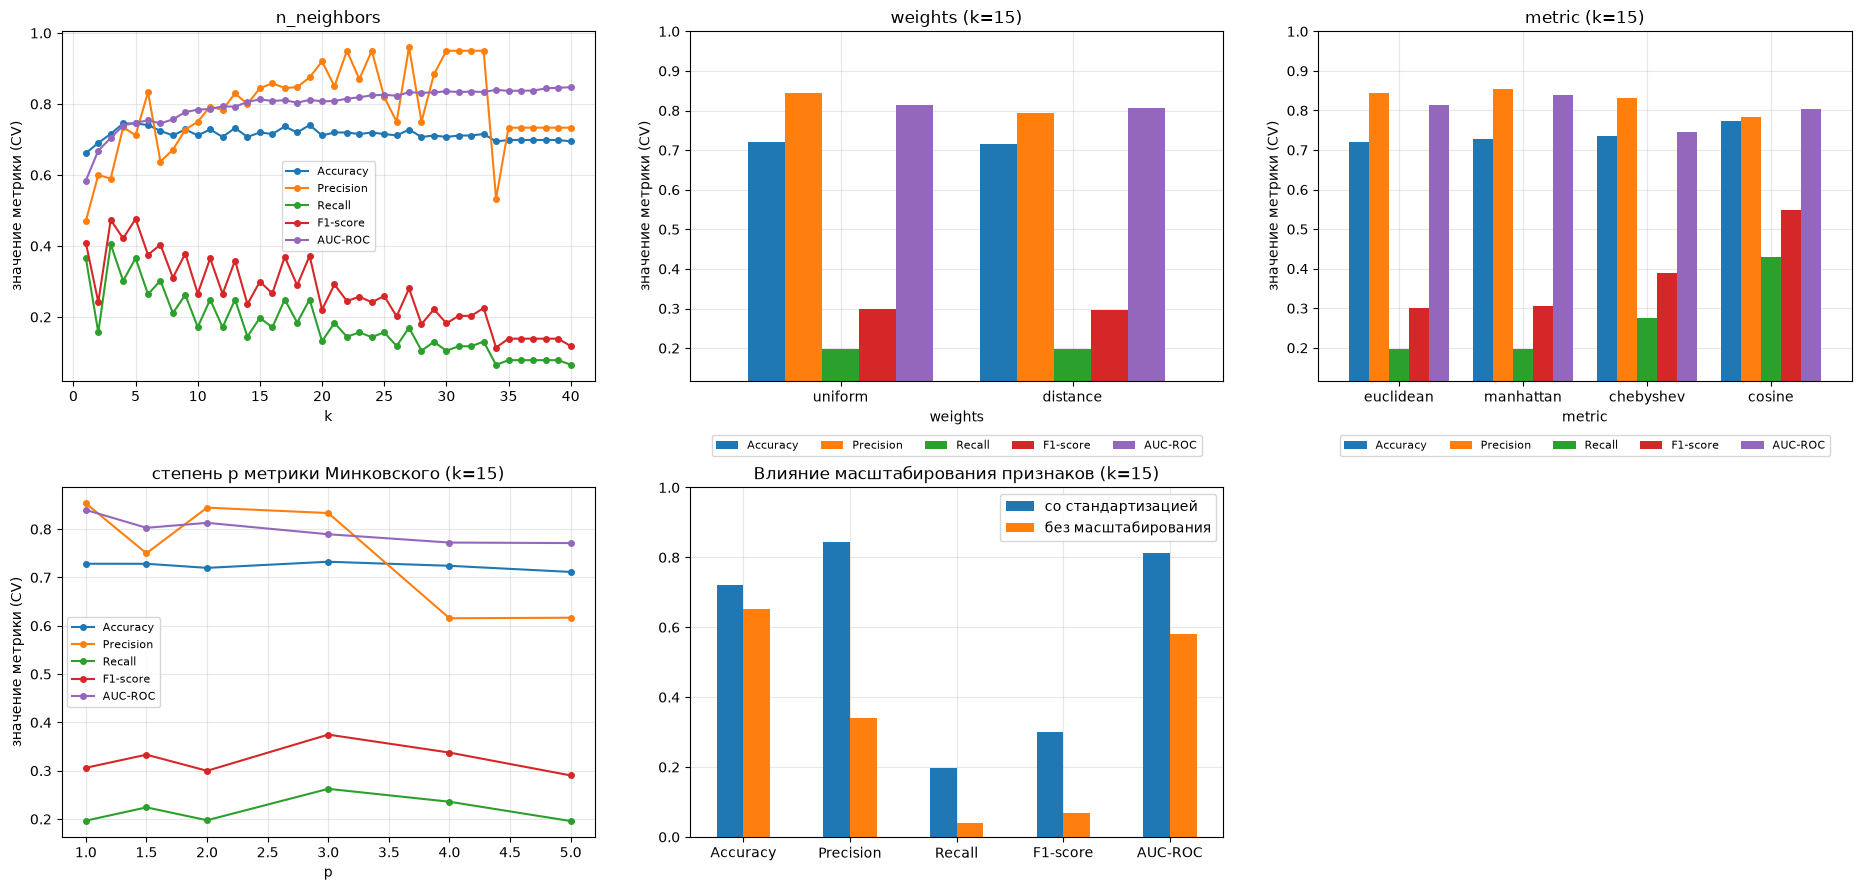

,со стандартизацией,без масштабирования
Accuracy,0.720,0.653
Precision,0.844,0.340
Recall,0.198,0.039
F1-score,0.300,0.068
AUC-ROC,0.813,0.580


In [18]:
base_knn = std(KNeighborsClassifier()).fit(X_train, y_train)
print("kNN по умолчанию (k=5), тест:", {NAMES[k]: round(v, 3) for k, v in test_metrics(base_knn).items()})

fig, axes = plt.subplots(2, 3, figsize=(19, 9))
ks = list(range(1, 41))
sw_k = sweep(lambda v: std(KNeighborsClassifier(n_neighbors=v)), "n_neighbors", ks)
plot_sweep(sw_k, "n_neighbors", "k", False, axes[0, 0])
plot_sweep(sweep(lambda v: std(KNeighborsClassifier(n_neighbors=15, weights=v)), "weights", ["uniform", "distance"]), "weights (k=15)", "weights", ax=axes[0, 1])
plot_sweep(sweep(lambda v: std(KNeighborsClassifier(n_neighbors=15, metric=v)), "metric", ["euclidean", "manhattan", "chebyshev", "cosine"]),
           "metric (k=15)", "metric", ax=axes[0, 2])
plot_sweep(sweep(lambda v: std(KNeighborsClassifier(n_neighbors=15, p=v)), "p", [1, 1.5, 2, 3, 4, 5]), "степень p метрики Минковского (k=15)", "p", False, axes[1, 0])
sc = pd.DataFrame({"со стандартизацией": cv_metrics(std(KNeighborsClassifier(n_neighbors=15))),
                   "без масштабирования": cv_metrics(KNeighborsClassifier(n_neighbors=15))}).rename(index=NAMES)
sc.plot.bar(ax=axes[1, 1], rot=0); axes[1, 1].set_title("Влияние масштабирования признаков (k=15)"); axes[1, 1].set_ylim(0, 1)
axes[1, 2].axis("off"); plt.tight_layout(); plt.show()
display(sc.round(3))

**Вывод.**
* **`n_neighbors`:** при k = 1 модель переобучена (AUC ≈ 0.58), с ростом k AUC монотонно растёт до ≈ 0.85 (k ≈ 40) — сглаживание граничной области помогает. Однако Recall при этом падает с ≈ 0.37 до ≈ 0.07: при большом k в окрестности чаще преобладает мажоритарный класс (65–70 %), и модель почти перестаёт предсказывать «умер». Precision при этом нестабильна (в окрестности малое число положительных объектов).
* **`weights`:** `uniform` и `distance` практически не различаются (AUC ≈ 0.81).
* **`metric`:** манхэттенское расстояние даёт наибольший AUC (≈ 0.84), евклидово ≈ 0.81, Чебышёва — худшее (≈ 0.73, учитывает только один максимальный по модулю признак); косинусная метрика даёт наибольший Recall (≈ 0.43) и F1 (≈ 0.55).
* **степень `p`:** рост p от 1 до 5 снижает AUC (0.84 → 0.77): чем больше p, тем сильнее метрика определяется одним признаком.
* **Масштабирование:** без стандартизации kNN почти неработоспособен: AUC 0.580 против 0.813, F1 0.068 против 0.300 — расстояния определяются признаком `platelets` (порядка 10⁵) и `creatinine_phosphokinase`, а остальные признаки игнорируются.

In [19]:
grid = {"clf__n_neighbors": list(range(1, 41)), "clf__weights": ["uniform", "distance"],
        "clf__metric": ["euclidean", "manhattan", "chebyshev"]}
gs_knn = tune("kNN", std(KNeighborsClassifier()), grid)

[kNN] лучшие параметры: {'clf__metric': 'manhattan', 'clf__n_neighbors': 39, 'clf__weights': 'distance'}
  CV AUC-ROC (train): 0.8615


,params,mean_test_score,std_test_score
0,"{'clf__metric': 'manhattan', 'clf__n_neighbors...",0.8615,0.0254
1,"{'clf__metric': 'manhattan', 'clf__n_neighbors...",0.8598,0.0249
2,"{'clf__metric': 'manhattan', 'clf__n_neighbors...",0.8587,0.0246
3,"{'clf__metric': 'manhattan', 'clf__n_neighbors...",0.8584,0.0269
4,"{'clf__metric': 'manhattan', 'clf__n_neighbors...",0.8584,0.0265


**Вывод.** Подбор выбрал `metric = manhattan`, `n_neighbors = 39`, `weights = distance` (CV AUC 0.862; значение k находится у верхней границы сетки, т.е. более крупное k возможно дало бы ещё небольшой рост AUC за счёт Recall). На тесте: AUC вырос с 0.800 (k = 5, по умолчанию) до 0.819, но Recall составил всего 0.053 при Precision 1.0 (модель предсказала «умер» лишь одному пациенту) — это следствие большого k и дисбаланса. Для задач, где важно найти больных, такой kNN непригоден без смещения порога.

### Промежуточное сравнение классических методов на тестовой выборке

In [20]:
classic = ["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB", "Decision Tree", "LDA", "SVM", "kNN"]
tbl = pd.DataFrame({n: results[n] for n in classic}).T.rename(columns={**NAMES, "cv_roc_auc": "CV AUC (train)"})
display(tbl.round(3))

,Accuracy,Precision,Recall,F1-score,AUC-ROC,CV AUC (train)
GaussianNB,0.717,0.750,0.158,0.261,0.845,0.867
MultinomialNB,0.683,0.000,0.000,0.000,0.774,0.837
ComplementNB,0.733,0.800,0.211,0.333,0.819,0.845
BernoulliNB,0.800,0.889,0.421,0.571,0.775,0.899
Decision Tree,0.833,0.909,0.526,0.667,0.852,0.886
LDA,0.800,0.769,0.526,0.625,0.865,0.886
SVM,0.817,0.900,0.474,0.621,0.868,0.888
kNN,0.700,1.000,0.053,0.100,0.819,0.861


## Нейронная сеть на TensorFlow

### Архитектура и обучение
Используется полносвязная сеть (многослойный перцептрон) `keras.Sequential`:
* **входной слой** — 12 стандартизованных признаков;
* **скрытые слои** `Dense(n, activation)` (+ `Dropout` для регуляризации);
* **выходной слой** `Dense(1, activation="sigmoid")` — вероятность класса «умер»;
* **функция потерь** — бинарная кросс-энтропия `binary_crossentropy`;
* **оптимизатор** — Adam (`learning_rate = 1e-3`); метрики — accuracy, AUC, precision, recall.

Из обучающей выборки выделяется **валидационная часть (20 %)**, по которой отслеживается обучение; тестовая выборка остаётся нетронутой до итоговой оценки. Признаки стандартизуются по статистикам обучающей части. Каждая конфигурация обучается с тремя разными инициализациями (seed 0, 1, 2), результаты усредняются — иначе из-за малого объёма данных случайность инициализации перекрывала бы эффект гиперпараметров. Все запуски пишутся в TensorBoard (`logs/`).

In [21]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
tf.keras.utils.set_random_seed(RANDOM_STATE)
tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__)

# валидационная часть из train + стандартизация по статистикам обучающей части
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
sc_nn = StandardScaler().fit(X_tr)
Xtr_s, Xval_s, Xte_s = (sc_nn.transform(a).astype("float32") for a in (X_tr, X_val, X_test))
ytr_a, yval_a, yte_a = y_tr.values.astype("float32"), y_val.values.astype("float32"), y_test.values.astype("float32")
print("train:", Xtr_s.shape, " val:", Xval_s.shape, " test:", Xte_s.shape)

LOG_ROOT = "logs"
shutil.rmtree(LOG_ROOT, ignore_errors=True)
OPT = {"adam": keras.optimizers.Adam, "sgd": keras.optimizers.SGD, "rmsprop": keras.optimizers.RMSprop}

def build_model(hidden=(16, 8), activation="relu", dropout=0.2, optimizer="adam", lr=1e-3, l2=0.0):
    m = keras.Sequential([layers.Input(shape=(Xtr_s.shape[1],))])
    for h in hidden:
        m.add(layers.Dense(h, activation=activation, kernel_regularizer=regularizers.l2(l2) if l2 else None))
        if dropout: m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=OPT[optimizer](learning_rate=lr), loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc"), keras.metrics.Precision(name="precision"), keras.metrics.Recall(name="recall")])
    return m

build_model().summary()

TensorFlow 2.22.0-rc1
train: (191, 12)  val: (48, 12)  test: (60, 12)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 353 (1.38 KB)

 Trainable params: 353 (1.38 KB)

 Non-trainable params: 0 (0.00 B)

**Описание архитектуры.** Базовая сеть `12 → 16 → 8 → 1` содержит 353 обучаемых параметра. Скрытые слои используют ReLU, `Dropout(0.2)` после каждого скрытого слоя снижает переобучение, выходной нейрон с сигмоидой даёт вероятность класса «умер». Функция потерь — бинарная кросс-энтропия, оптимизатор — Adam.

In [27]:
from pathlib import Path

SEEDS = (0, 1, 2)
histories = {}      # (группа, имя) -> список history.history по seed

def make_log_dir(*parts):
    """Создаёт папку для логов и возвращает АБСОЛЮТНЫЙ путь со слэшами '/'
    (TensorFlow на Windows плохо работает с относительными путями с '\\')."""
    cur = Path(LOG_ROOT).resolve()
    if cur.is_file():
        cur.unlink()
    for part in parts:
        cur = cur / part
        if cur.is_file():
            cur.unlink()
    cur.mkdir(parents=True, exist_ok=True)
    return cur.as_posix()      # <-- строка вида 'C:/.../logs/7_final/final_model'


def run_experiment(group, name, epochs=100, batch_size=16, callbacks=None, **model_kw):
    hs = []
    for s in SEEDS:
        tf.keras.utils.set_random_seed(s)
        m = build_model(**model_kw)
        log_dir = make_log_dir(group, name, f"seed{s}")
        cbs = []   # если логи не нужны: cbs = []
        h = m.fit(Xtr_s, ytr_a, validation_data=(Xval_s, yval_a),
                  epochs=epochs, batch_size=batch_size, verbose=0,
                  callbacks=cbs + (callbacks or []))
        hs.append(h.history)
    histories[(group, name)] = hs
    return hs

    
def mean_hist(hs, key):
    return np.mean([h[key] for h in hs], axis=0)

def summary_at(group, names, epoch=None):
    # средние по seed значения на валидации на указанной эпохе (по умолчанию - последней)
    rows = []
    for n in names:
        hs = histories[(group, n)]; e = (len(hs[0]["loss"]) - 1) if epoch is None else epoch - 1
        g = lambda k: float(np.mean([h[k][e] for h in hs]))
        p, r = g("val_precision"), g("val_recall")
        rows.append({"конфигурация": n, "train loss": g("loss"), "val loss": g("val_loss"), "train acc": g("accuracy"), "val acc": g("val_accuracy"),
                     "val AUC": g("val_auc"), "val precision": p, "val recall": r, "val F1": 2 * p * r / (p + r + 1e-9)})
    return pd.DataFrame(rows).set_index("конфигурация")

def plot_curves(group, names, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8)); cols = plt.cm.tab10.colors
    for i, n in enumerate(names):
        hs = histories[(group, n)]
        for ax, k, lab in zip(axes, ["loss", "accuracy"], ["Loss", "Accuracy"]):
            ax.plot(mean_hist(hs, k), color=cols[i % 10], label=f"{n} (train)")
            ax.plot(mean_hist(hs, "val_" + k), color=cols[i % 10], ls="--", label=f"{n} (val)")
            ax.set_xlabel("эпоха"); ax.set_ylabel(lab); ax.set_title(f"{title}: {lab}")
    axes[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

### Эксперимент 1. Число эпох
Базовая сеть `16-8` (ReLU, dropout 0.2, batch 16) обучается 300 эпох; по кривым train/val видно, когда начинается переобучение.

In [23]:
from pathlib import Path

print("LOG_ROOT:", LOG_ROOT)
print("существует:", Path(LOG_ROOT).exists())
print("это папка:", Path(LOG_ROOT).is_dir())

LOG_ROOT: logs
существует: False
это папка: False


In [24]:
import shutil
from pathlib import Path

log_path = Path(LOG_ROOT)

if log_path.is_file():
    log_path.unlink()
elif log_path.is_dir():
    shutil.rmtree(log_path)

log_path.mkdir(parents=True, exist_ok=True)

print("Папка логов успешно создана:", log_path)

Папка логов успешно создана: logs


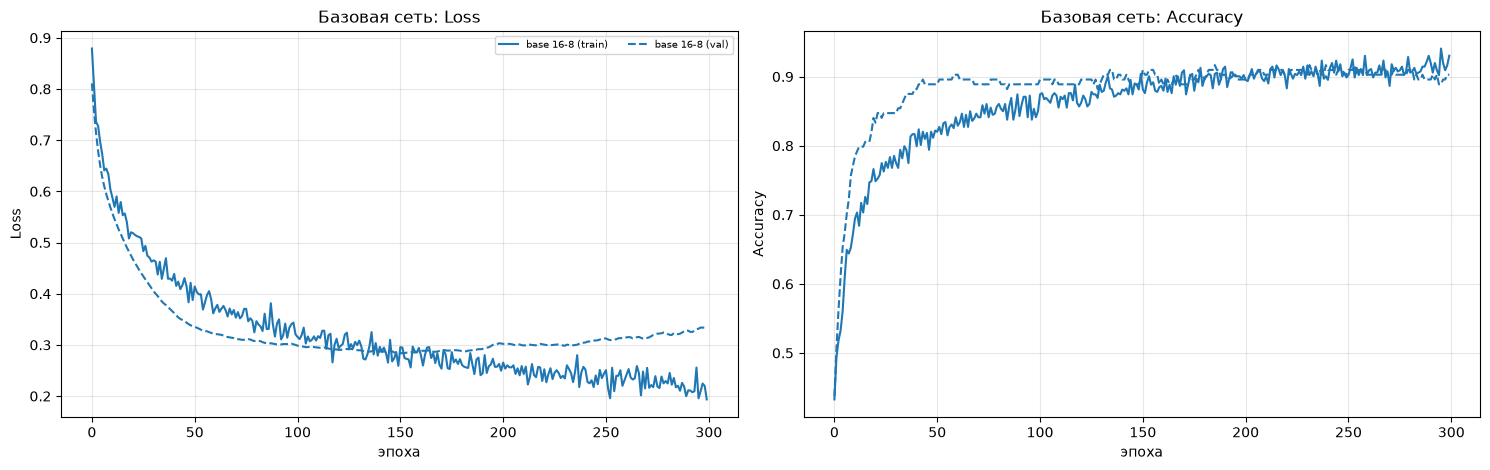

Эпоха минимального val_loss (среднее по seed): 151 , val_loss = 0.2837


,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
5 эпох,0.697,0.651,0.560,0.653,0.701,0.473,0.733,0.575
10 эпох,0.604,0.568,0.672,0.771,0.781,0.722,0.489,0.583
25 эпох,0.508,0.440,0.763,0.847,0.898,0.811,0.667,0.732
50 эпох,0.388,0.337,0.822,0.889,0.939,0.823,0.822,0.823
100 эпох,0.321,0.300,0.850,0.889,0.947,0.808,0.844,0.826
200 эпох,0.250,0.303,0.902,0.896,0.945,0.813,0.867,0.839
300 эпох,0.194,0.334,0.930,0.903,0.939,0.815,0.889,0.850


In [28]:
run_experiment("1_epochs", "base 16-8", epochs=300)
plot_curves("1_epochs", ["base 16-8"], "Базовая сеть")
hs = histories[("1_epochs", "base 16-8")]
best_ep = int(np.argmin(mean_hist(hs, "val_loss"))) + 1
print("Эпоха минимального val_loss (среднее по seed):", best_ep, ", val_loss = %.4f" % mean_hist(hs, "val_loss").min())
rows = []
for e in [5, 10, 25, 50, 100, 200, 300]:
    r = summary_at("1_epochs", ["base 16-8"], e).iloc[0]; r.name = f"{e} эпох"; rows.append(r)
display(pd.DataFrame(rows).round(3))

**Вывод.** Сеть быстро обучается: к 25-й эпохе val accuracy достигает 0.83, к 50-й — 0.90 (AUC 0.94). Минимум val loss (0.282) достигается около 153-й эпохи; дальше train loss продолжает падать (0.305 → 0.225 к 300-й эпохе), а val loss растёт (0.292 → 0.336) — начинается переобучение (расхождение кривых). Если эпох слишком мало (5–10), модель недообучена (val accuracy 0.65–0.79, AUC 0.69–0.77). Поэтому для итоговой модели используется ранняя остановка.

### Эксперимент 2. Размер батча

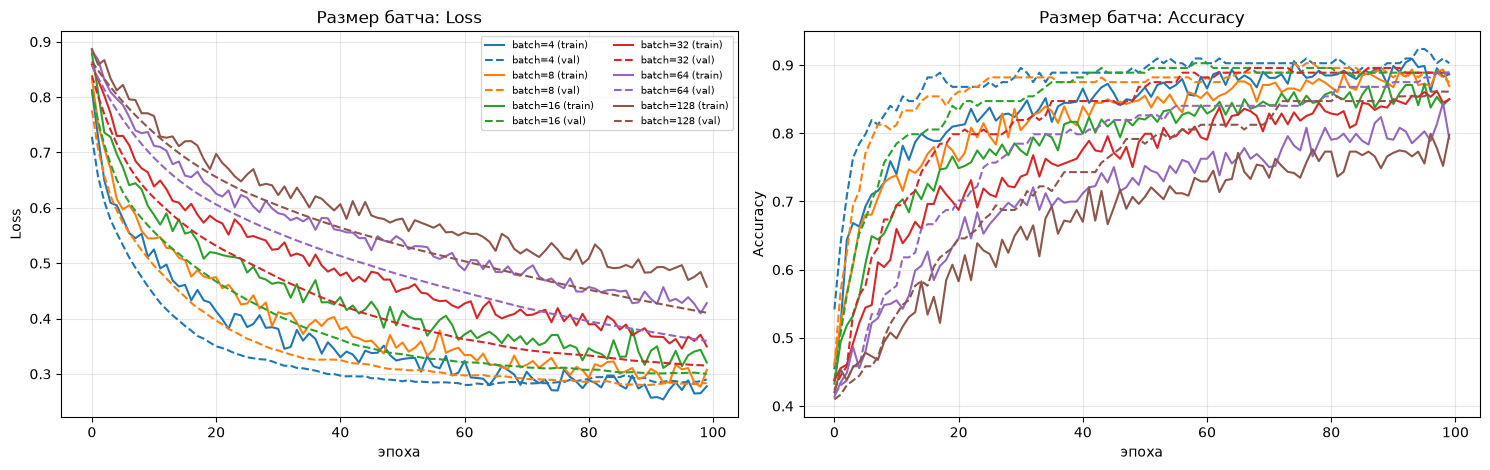

,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
конфигурация,,,,,,,,
batch=4,0.278,0.290,0.887,0.903,0.947,0.831,0.867,0.848
batch=8,0.307,0.283,0.869,0.875,0.947,0.800,0.800,0.800
batch=16,0.321,0.300,0.850,0.889,0.947,0.808,0.844,0.826
batch=32,0.350,0.315,0.850,0.889,0.944,0.807,0.844,0.825
batch=64,0.428,0.360,0.792,0.889,0.937,0.838,0.800,0.818
batch=128,0.457,0.411,0.798,0.861,0.913,0.805,0.733,0.767


In [29]:
bs_names = []
for bs in [4, 8, 16, 32, 64, 128]:
    n = f"batch={bs}"; bs_names.append(n); run_experiment("2_batch", n, epochs=100, batch_size=bs)
plot_curves("2_batch", bs_names, "Размер батча")
display(summary_at("2_batch", bs_names).round(3))

**Вывод.** Малые батчи (4–16) дают более быструю сходимость за фиксированное число эпох (train loss 0.28–0.31, val AUC ≈ 0.945) — больше шагов градиента за эпоху, но кривые зашумлены и обучение медленнее по времени. Большие батчи (64–128) к 100-й эпохе недообучены (для 128: train loss 0.485, val accuracy 0.84, val AUC 0.903, Recall 0.69): за те же 100 эпох делается меньше обновлений весов. Разницы между 8, 16 и 32 практически нет; выбран размер 16 как компромисс между скоростью и стабильностью.

### Эксперимент 3. Число слоёв и нейронов

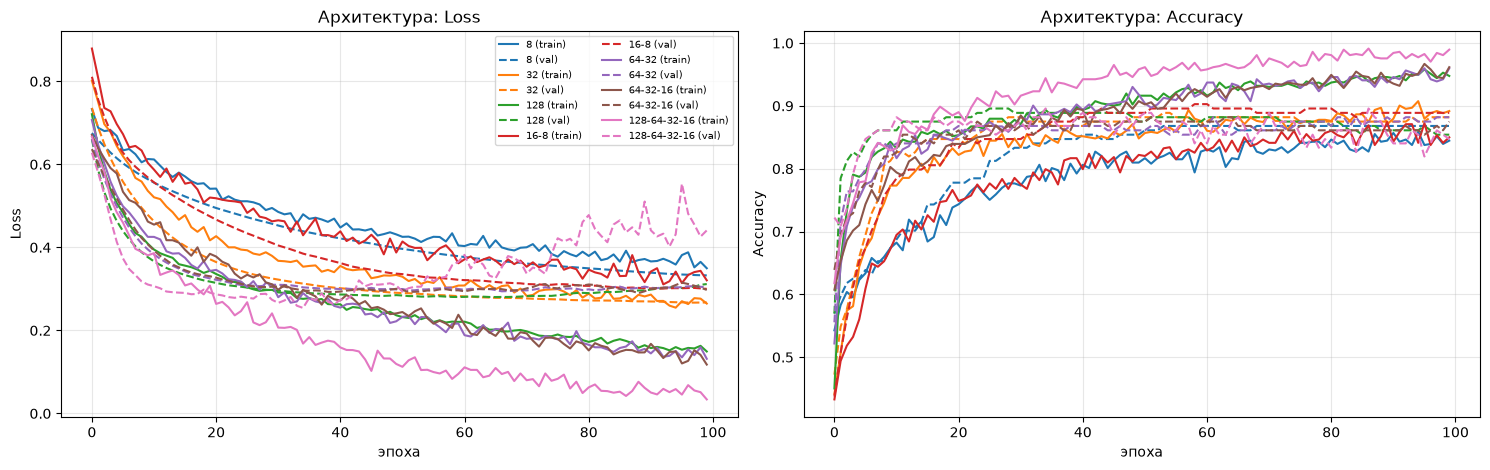

,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
конфигурация,,,,,,,,
8,0.350,0.333,0.845,0.868,0.938,0.795,0.778,0.786
32,0.265,0.267,0.892,0.882,0.953,0.796,0.844,0.819
128,0.149,0.312,0.948,0.854,0.935,0.731,0.844,0.784
16-8,0.321,0.300,0.850,0.889,0.947,0.808,0.844,0.826
64-32,0.132,0.304,0.960,0.882,0.939,0.796,0.844,0.819
64-32-16,0.118,0.298,0.962,0.875,0.945,0.755,0.889,0.816
128-64-32-16,0.034,0.441,0.990,0.847,0.927,0.735,0.800,0.766


In [30]:
arch = {"8": (8,), "32": (32,), "128": (128,), "16-8": (16, 8), "64-32": (64, 32), "64-32-16": (64, 32, 16), "128-64-32-16": (128, 64, 32, 16)}
for n, h in arch.items(): run_experiment("3_arch", n, epochs=100, hidden=h)
plot_curves("3_arch", list(arch), "Архитектура")
display(summary_at("3_arch", list(arch)).round(3))

**Вывод.** Слишком маленькая сеть (8 нейронов) недообучается (train loss 0.368, val F1 0.774). С ростом ёмкости train loss падает (до 0.037 у `128-64-32-16`), но val loss после минимума растёт: у самой глубокой сети train accuracy 0.986 при val loss 0.451 — явное переобучение. Лучшее значение val loss (0.266) и val AUC (0.954) — у однослойной сети с 32 нейронами; у `16-8` лучшие val accuracy (0.896) и F1 (0.838). На небольшом датасете (191 объект в обучении) глубокие сети не дают преимущества: простые архитектуры достаточны, а чем больше параметров, тем выше риск запомнить обучающую выборку. Для дальнейшей работы выбрана умеренная `32-16`.

### Эксперимент 4. Функции активации скрытых слоёв

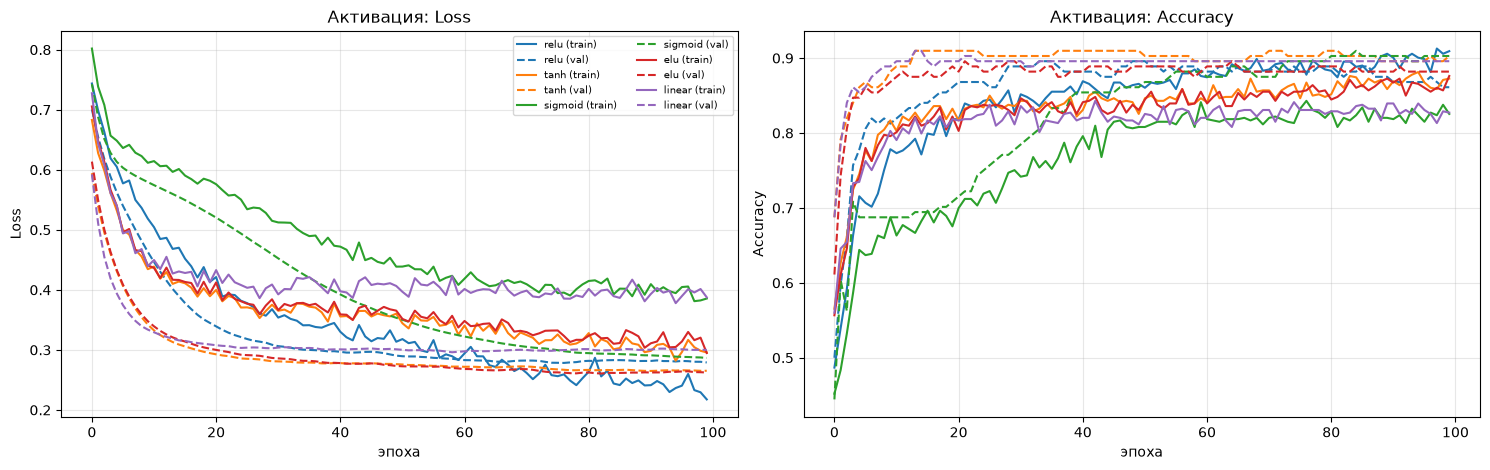

,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
конфигурация,,,,,,,,
relu,0.218,0.279,0.909,0.861,0.940,0.778,0.778,0.778
tanh,0.296,0.265,0.873,0.903,0.953,0.793,0.933,0.857
sigmoid,0.386,0.287,0.825,0.903,0.949,0.816,0.889,0.851
elu,0.295,0.262,0.876,0.882,0.951,0.792,0.844,0.817
linear,0.388,0.300,0.827,0.896,0.953,0.812,0.867,0.839


In [31]:
acts = ["relu", "tanh", "sigmoid", "elu", "linear"]
for a in acts: run_experiment("4_act", a, epochs=100, hidden=(32, 16), activation=a)
plot_curves("4_act", acts, "Активация")
display(summary_at("4_act", acts).round(3))

**Вывод.** Различия между функциями активации небольшие (val AUC 0.939–0.952). `tanh` показывает лучший val F1 (0.845) и Recall (0.911), `elu` — наименьший val loss (0.259). `sigmoid` обучается медленнее (train loss 0.397 к 100-й эпохе из-за затухающих градиентов), `relu` быстрее всех снижает train loss (0.240). Интересно, что даже полностью линейная активация (`linear`, эквивалентна логистической регрессии) даёт val AUC 0.951 — это подтверждает, что классы в основном разделяются линейно (как показали LDA и линейный SVM).

### Эксперимент 5. Оптимизатор, скорость обучения и регуляризация

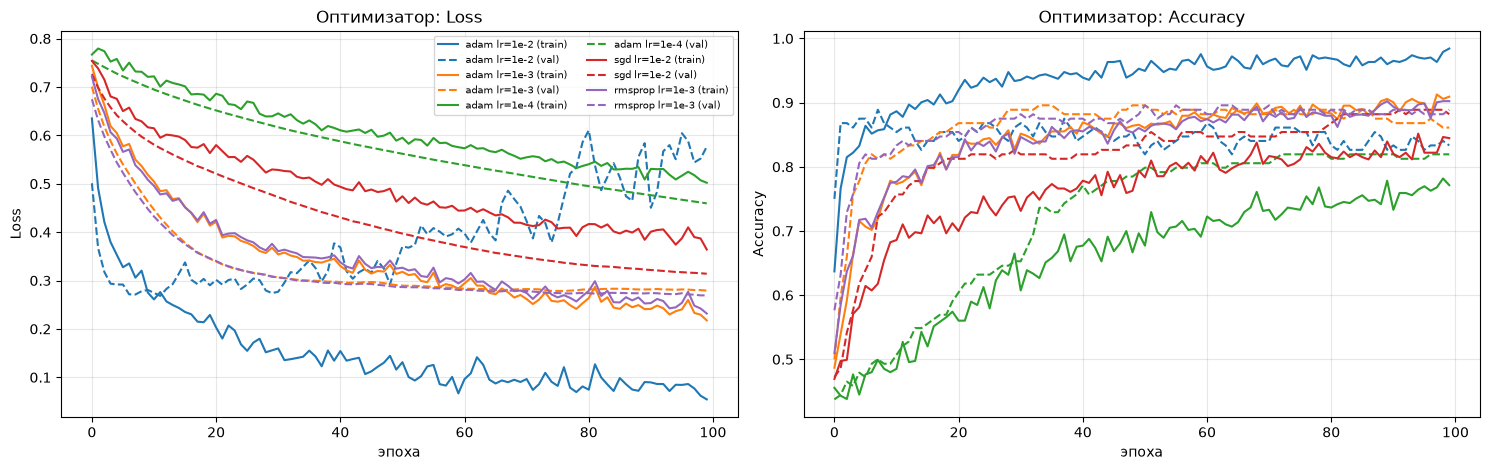

,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
конфигурация,,,,,,,,
adam lr=1e-2,0.054,0.577,0.984,0.833,0.919,0.717,0.778,0.746
adam lr=1e-3,0.218,0.279,0.909,0.861,0.940,0.778,0.778,0.778
adam lr=1e-4,0.502,0.459,0.771,0.819,0.901,0.828,0.533,0.649
sgd lr=1e-2,0.364,0.314,0.845,0.882,0.952,0.818,0.800,0.809
rmsprop lr=1e-3,0.232,0.269,0.902,0.889,0.944,0.822,0.822,0.822


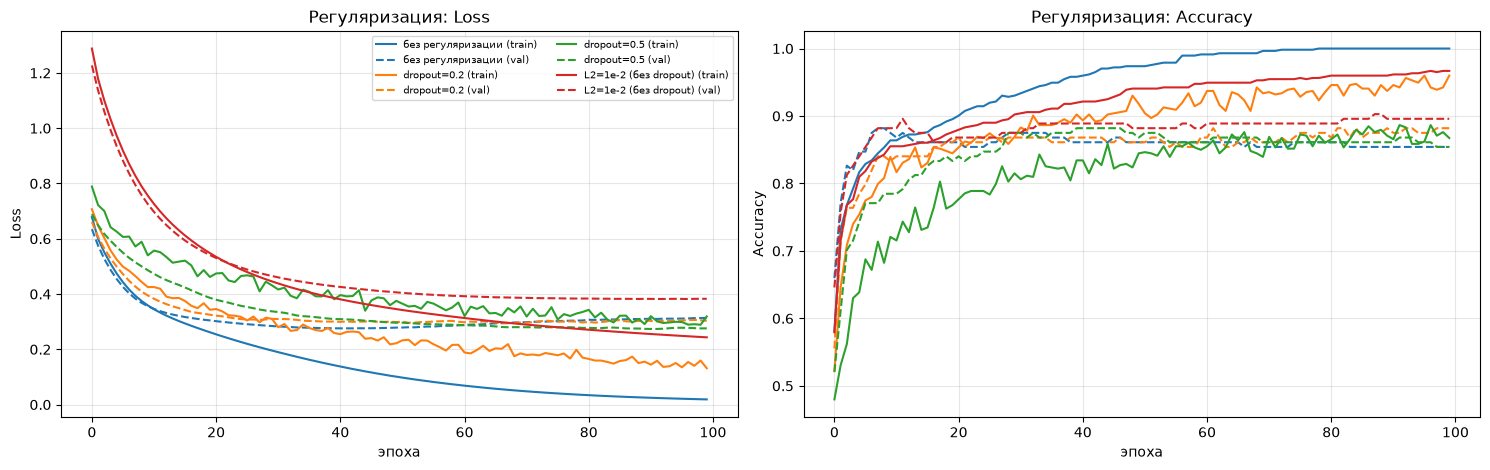

,train loss,val loss,train acc,val acc,val AUC,val precision,val recall,val F1
конфигурация,,,,,,,,
без регуляризации,0.019,0.314,1.000,0.854,0.951,0.731,0.844,0.784
dropout=0.2,0.132,0.304,0.960,0.882,0.939,0.796,0.844,0.819
dropout=0.5,0.319,0.276,0.867,0.854,0.948,0.749,0.800,0.774
L2=1e-2 (без dropout),0.243,0.383,0.967,0.896,0.946,0.815,0.867,0.840


In [32]:
opts = {"adam lr=1e-2": dict(optimizer="adam", lr=1e-2), "adam lr=1e-3": dict(optimizer="adam", lr=1e-3), "adam lr=1e-4": dict(optimizer="adam", lr=1e-4),
        "sgd lr=1e-2": dict(optimizer="sgd", lr=1e-2), "rmsprop lr=1e-3": dict(optimizer="rmsprop", lr=1e-3)}
for n, kw in opts.items(): run_experiment("5_opt", n, epochs=100, hidden=(32, 16), **kw)
plot_curves("5_opt", list(opts), "Оптимизатор")
display(summary_at("5_opt", list(opts)).round(3))

reg = {"без регуляризации": dict(dropout=0), "dropout=0.2": dict(dropout=0.2), "dropout=0.5": dict(dropout=0.5), "L2=1e-2 (без dropout)": dict(dropout=0, l2=1e-2)}
for n, kw in reg.items(): run_experiment("6_reg", n, epochs=100, hidden=(64, 32), **kw)
plot_curves("6_reg", list(reg), "Регуляризация")
display(summary_at("6_reg", list(reg)).round(3))

**Вывод.**
* **Оптимизатор и скорость обучения.** Adam с `lr = 0.01` слишком агрессивен: train loss 0.080, но val loss 0.455 — переобучение. `lr = 1e-4` слишком мал: к 100-й эпохе сеть недообучена (train accuracy 0.759, Recall 0.556). `lr = 1e-3` — хороший баланс. SGD (`lr = 0.01`) сходится медленнее (train loss 0.400), но не переобучается и даёт val AUC 0.950; RMSprop близок к Adam.
* **Регуляризация** (сеть `64-32`). Без регуляризации сеть доходит до train accuracy 1.0 (train loss 0.018) при val loss 0.313 — переобучение; `dropout = 0.5` даёт наименьший val loss (0.275) и сближает train/val кривые (train loss 0.297). L2-регуляризация (`1e-2`) даёт val accuracy 0.896, но её значение loss включает штраф за веса, поэтому с остальными напрямую не сравнивается.

### Итоговая нейронная сеть
По результатам экспериментов выбирается конфигурация, а чтобы не зависеть от числа эпох, обучение выполняется с **ранней остановкой** (`EarlyStopping` по `val_loss`, возвращаются веса лучшей эпохи). Итоговая оценка — на тестовой выборке.

In [33]:
from pathlib import Path
import os

print("LOG_ROOT =", repr(LOG_ROOT))
print("Абсолютный путь =", Path(LOG_ROOT).resolve())
print("Существует =", Path(LOG_ROOT).exists())
print("Это файл =", Path(LOG_ROOT).is_file())
print("Это папка =", Path(LOG_ROOT).is_dir())

print("\nСодержимое текущей директории:")
for p in Path.cwd().iterdir():
    if p.name.lower() == "logs":
        print(p, "| папка:", p.is_dir(), "| файл:", p.is_file())

LOG_ROOT = 'logs'
Абсолютный путь = D:\рабочий стол\lab2\logs
Существует = True
Это файл = False
Это папка = True

Содержимое текущей директории:
d:\рабочий стол\lab2\logs | папка: True | файл: False


Остановка на эпохе: 106 , лучшая эпоха: 81


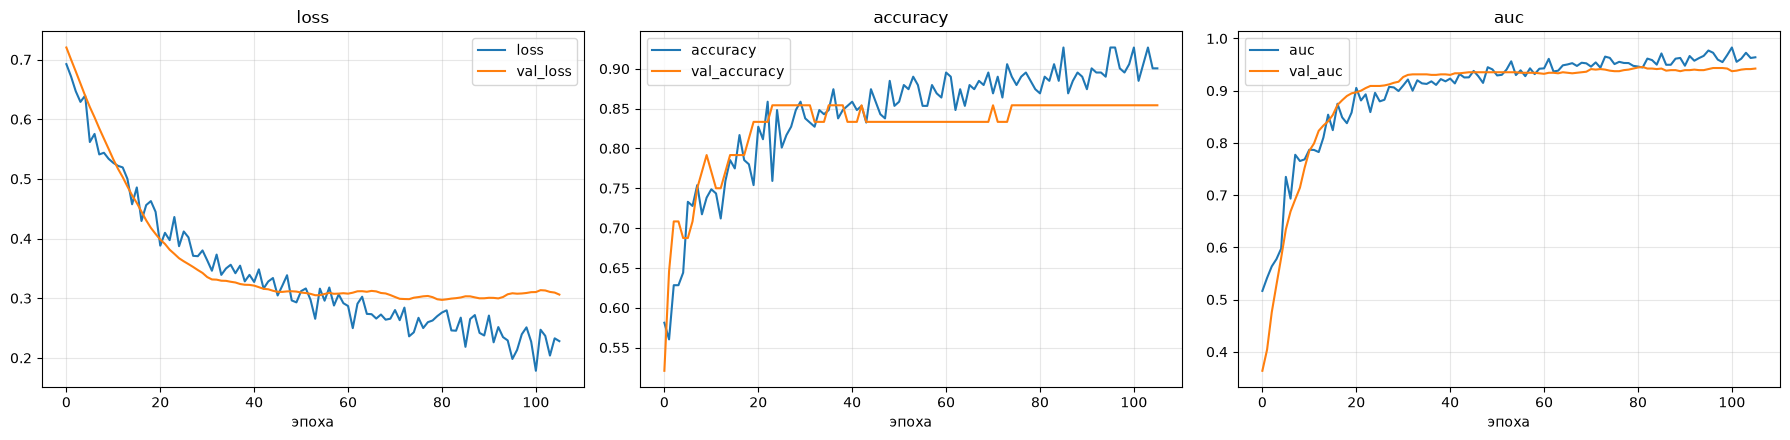

,Accuracy,Precision,Recall,F1-score,AUC-ROC
Neural Network,0.767,0.692,0.474,0.562,0.815


In [35]:
FINAL_CFG = dict(hidden=(32, 16), activation="relu", dropout=0.2, optimizer="adam", lr=1e-3)
tf.keras.utils.set_random_seed(RANDOM_STATE)
nn = build_model(**FINAL_CFG)
es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)

log_dir = make_log_dir("7_final", "final_model")   # уже абсолютный путь с '/'
tb = keras.callbacks.TensorBoard(log_dir=log_dir)

h = nn.fit(Xtr_s, ytr_a, validation_data=(Xval_s, yval_a),
           epochs=300, batch_size=16, verbose=0, callbacks=[es])

n_epochs = len(h.history["loss"])
best_epoch = getattr(es, "best_epoch", n_epochs - es.patience - 1) + 1   # нумерация с 1
print("Остановка на эпохе:", n_epochs, ", лучшая эпоха:", best_epoch)

hh = pd.DataFrame(h.history)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, k in zip(axes, ["loss", "accuracy", "auc"]):
    hh[[k, "val_" + k]].plot(ax=ax); ax.set_title(k); ax.set_xlabel("эпоха")
plt.tight_layout(); plt.show()


class KerasWrap:   # обёртка, чтобы использовать единые функции метрик
    def __init__(self, m, scaler):
        self.m, self.sc = m, scaler

    def _x(self, X_):
        return self.sc.transform(X_).astype("float32")

    def predict_proba(self, X_):
        p = self.m.predict(self._x(X_), verbose=0).ravel()
        return np.c_[1 - p, p]

    def predict(self, X_):
        return (self.predict_proba(X_)[:, 1] >= 0.5).astype(int)


nn_model = KerasWrap(nn, sc_nn)
results["Neural Network"] = test_metrics(nn_model); models["Neural Network"] = nn_model
results["Neural Network"]["cv_roc_auc"] = np.nan      # будет рассчитан ниже кросс-валидацией
display(pd.DataFrame({"Neural Network": results["Neural Network"]}).T[METRICS].rename(columns=NAMES).round(3))


**Вывод.** Итоговая сеть `12 → 32 → 16 → 1` (ReLU, dropout 0.2, Adam 10⁻³, batch 16) остановлена на 153-й эпохе (лучшая — 128-я): val loss выходит на плато около 0.30, а train loss продолжает падать — ранняя остановка предотвратила переобучение. На тесте получено: Accuracy 0.767, Precision 0.692, Recall 0.474, F1 0.562, AUC 0.804.

#### Надёжность оценки нейросети
Валидационная часть (48 объектов) и тестовая (60 объектов) очень малы, а результат одной сети зависит от инициализации. Поэтому дополнительно оцениваем выбранную конфигурацию (а) на тесте по 5 разным инициализациям и (б) 5-кратной стратифицированной кросс-валидацией на обучающей выборке (100 эпох, масштабирование внутри фолда) — это делает AUC нейросети сопоставимым со столбцом «CV AUC (train)» у остальных методов.

In [36]:
rows = []
for s in range(5):
    tf.keras.utils.set_random_seed(s)
    m_ = build_model(**FINAL_CFG)
    es_ = keras.callbacks.EarlyStopping(monitor="val_loss", patience=25, restore_best_weights=True)
    m_.fit(Xtr_s, ytr_a, validation_data=(Xval_s, yval_a), epochs=300, batch_size=16, verbose=0, callbacks=[es_])
    rows.append(test_metrics(KerasWrap(m_, sc_nn)))
seed_tbl = pd.DataFrame(rows).rename(columns=NAMES)
display(pd.DataFrame({"среднее": seed_tbl.mean(), "std": seed_tbl.std()}).T.round(3))

cv_auc = []
for k, (tr, va) in enumerate(cv.split(X_train, y_train)):
    tf.keras.utils.set_random_seed(k)
    sc_ = StandardScaler().fit(X_train.iloc[tr])
    m_ = build_model(**FINAL_CFG)
    m_.fit(sc_.transform(X_train.iloc[tr]).astype("float32"), y_train.iloc[tr].values.astype("float32"), epochs=100, batch_size=16, verbose=0)
    p_ = m_.predict(sc_.transform(X_train.iloc[va]).astype("float32"), verbose=0).ravel()
    cv_auc.append(roc_auc_score(y_train.iloc[va], p_))
print("CV AUC-ROC нейросети по фолдам:", np.round(cv_auc, 3), "-> среднее %.4f" % np.mean(cv_auc))
results["Neural Network"]["cv_roc_auc"] = float(np.mean(cv_auc))

,Accuracy,Precision,Recall,F1-score,AUC-ROC
среднее,0.743,0.628,0.474,0.539,0.814
std,0.019,0.046,0.037,0.030,0.012


CV AUC-ROC нейросети по фолдам: [0.82  0.891 0.861 0.904 0.879] -> среднее 0.8712


**Вывод.** По 5 инициализациям средний тестовый AUC равен 0.811 ± 0.015, F1 — 0.545 ± 0.031, т.е. значение 0.804 не случайно занижено. Кросс-валидационный AUC нейросети — 0.867 (по фолдам 0.81–0.89), что сопоставимо с классическими методами (LDA и SVM — 0.886–0.888, дерево — 0.886 на тех же фолдах), но чуть ниже. Таким образом, нейросеть на таком малом датасете не превосходит простые линейные модели. Высокий AUC на валидационной части (0.94) был оптимистичным из-за малого размера этой части (48 объектов).

### Мониторинг через TensorBoard
Логи всех запусков сохранены в каталоге `logs/` (подкаталоги — группы экспериментов, затем конфигурации и seed). Для просмотра:

```bash
tensorboard --logdir logs
```
затем открыть http://localhost:6006 (вкладки *Scalars*, *Graphs*, *Distributions/Histograms*). В Jupyter можно также выполнить `%load_ext tensorboard` и `%tensorboard --logdir logs`. На вкладке *Scalars* для каждого запуска доступны кривые `epoch_loss`, `epoch_accuracy`, `epoch_auc`, `epoch_precision`, `epoch_recall` и те же метрики на валидации (`validation`).

Ниже приведён скриншот TensorBoard (вкладка *Scalars*) для итоговой модели `7_final` и базовой сети из эксперимента 1 (`1_epochs`, три seed): сплошные линии — обучение (`train`), остальные — валидация (`validation`); видно расхождение кривых accuracy и AUC на обучении и валидации при росте числа эпох.

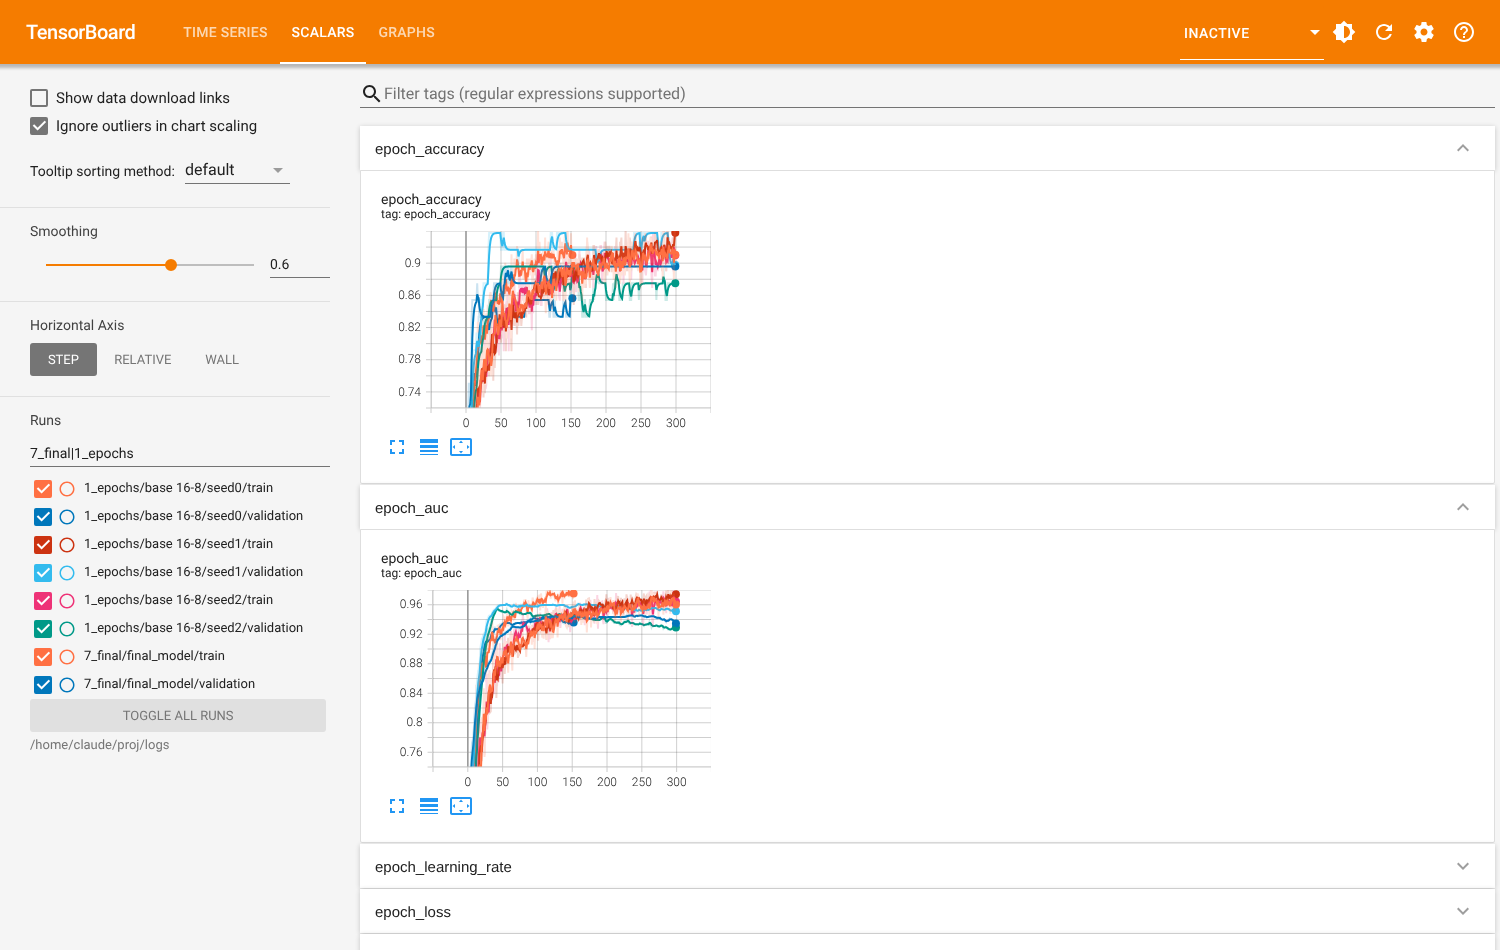

## Сравнительный анализ

In [38]:
order = ["GaussianNB", "MultinomialNB", "ComplementNB", "BernoulliNB", "Decision Tree", "LDA", "SVM", "kNN", "Neural Network"]
final = pd.DataFrame({n: results[n] for n in order}).T[METRICS].rename(columns=NAMES)
display(final.round(3).style.background_gradient(cmap="Greens", axis=0).format("{:.3f}"))

print("Лучший метод по каждой метрике:")
print(final.idxmax().to_string())

,Accuracy,Precision,Recall,F1-score,AUC-ROC
GaussianNB,0.717,0.750,0.158,0.261,0.845
MultinomialNB,0.683,0.000,0.000,0.000,0.774
ComplementNB,0.733,0.800,0.211,0.333,0.819
BernoulliNB,0.800,0.889,0.421,0.571,0.775
Decision Tree,0.833,0.909,0.526,0.667,0.852
LDA,0.800,0.769,0.526,0.625,0.865
SVM,0.817,0.900,0.474,0.621,0.868
kNN,0.700,1.000,0.053,0.100,0.819
Neural Network,0.767,0.692,0.474,0.562,0.815


Лучший метод по каждой метрике:
Accuracy     Decision Tree
Precision              kNN
Recall       Decision Tree
F1-score     Decision Tree
AUC-ROC                SVM


**Вывод.** По тестовой выборке лучшие значения: Accuracy, Recall и F1 — у дерева решений (0.833 / 0.526 / 0.667), AUC-ROC — у SVM (0.868; LDA — 0.865), Precision — у kNN (1.0, но при Recall = 0.053, т.е. на единичных предсказаниях). Метрики Precision/Recall при пороге 0.5 существенно зависят от дисбаланса классов, тогда как AUC характеризует качество ранжирования независимо от порога. Хуже всего — MultinomialNB (не предсказывает класс 1 вообще) и kNN (практически не находит умерших).

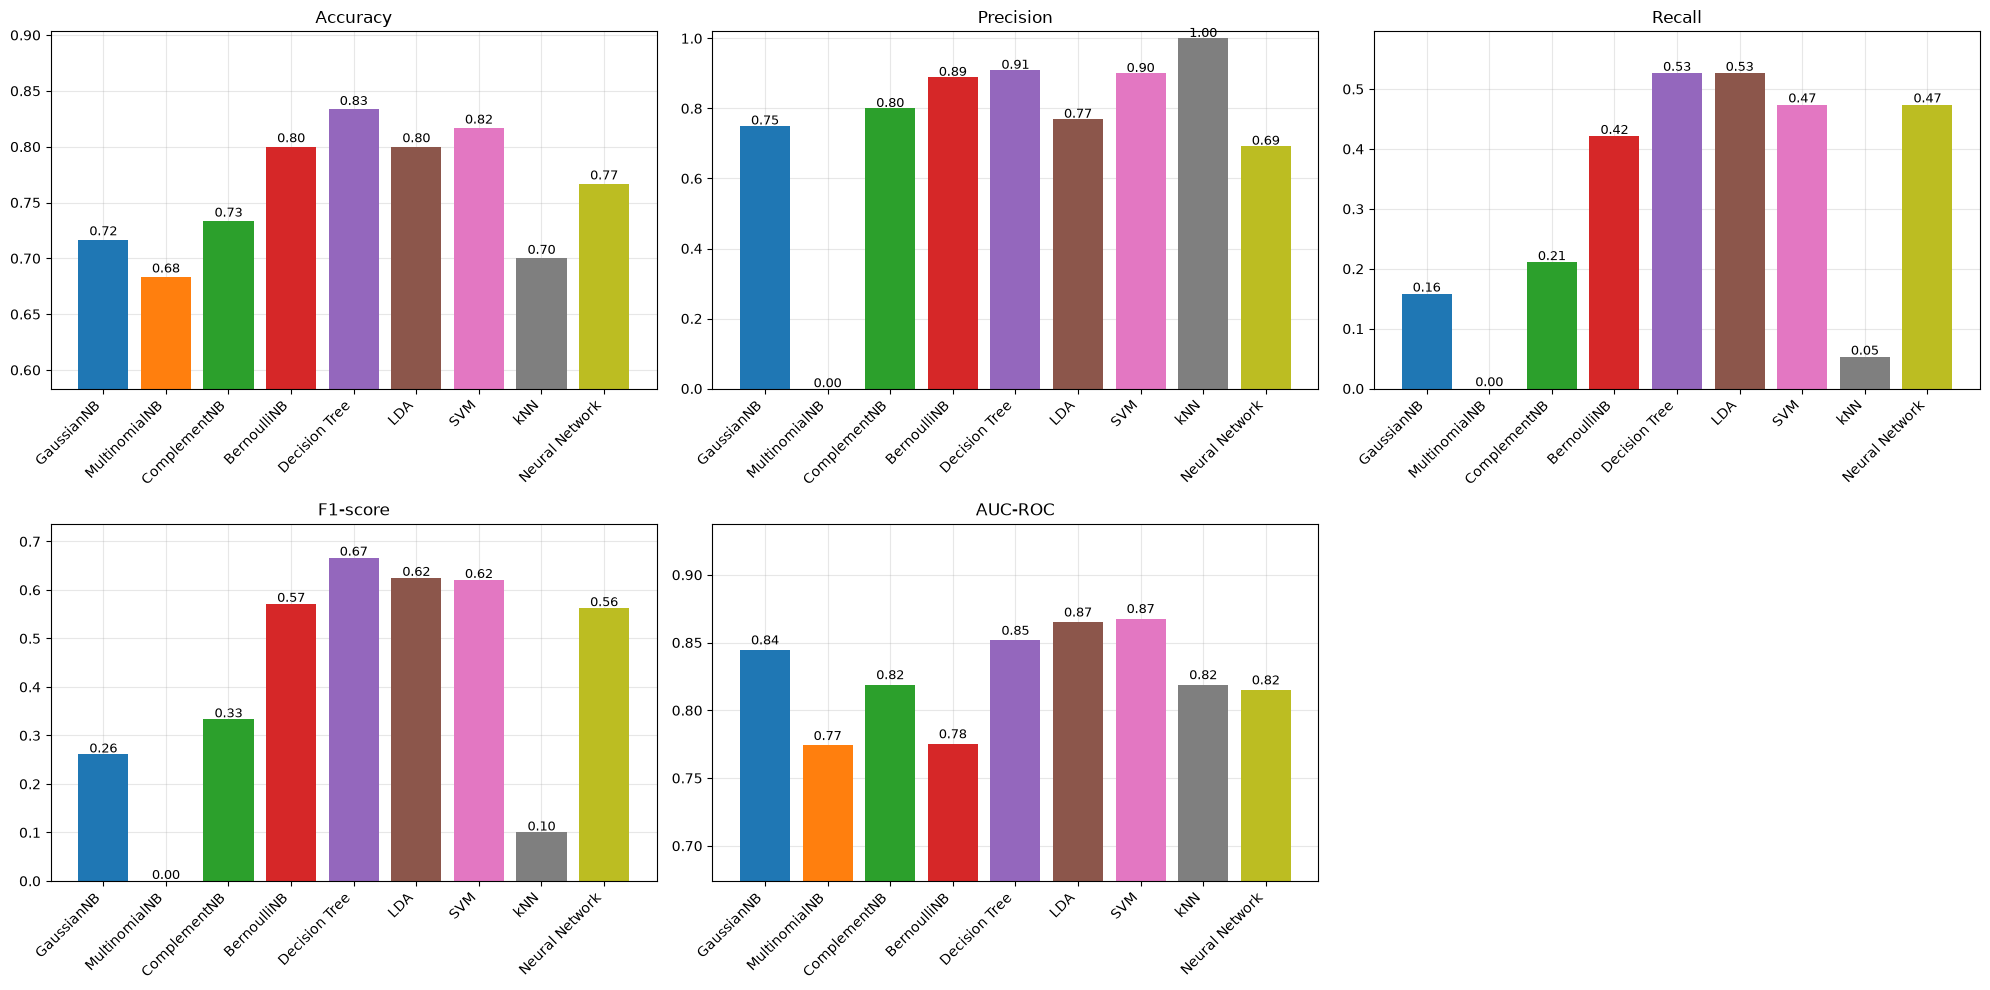

In [39]:
# столбчатые диаграммы по каждой метрике
fig, axes = plt.subplots(2, 3, figsize=(20, 10)); cols = sns.color_palette("tab10", len(order))
for ax, m in zip(axes.ravel(), METRICS):
    vals = final[NAMES[m]]
    ax.bar(range(len(order)), vals, color=cols); ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=45, ha="right")
    ax.set_ylim(max(0, vals.min() - 0.1), min(1.02, vals.max() + 0.07)); ax.set_title(NAMES[m])
    for i, v in enumerate(vals): ax.text(i, v + 0.004, f"{v:.2f}", ha="center", fontsize=9)
axes.ravel()[-1].axis("off"); plt.tight_layout(); plt.show()

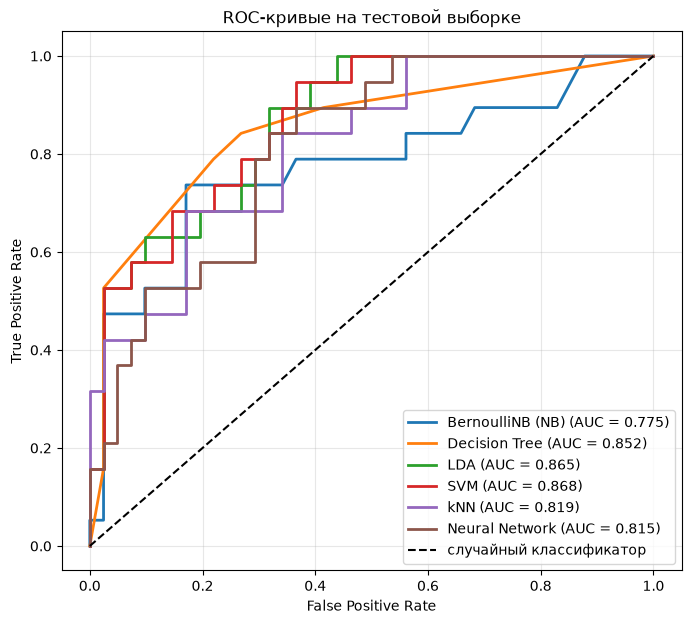

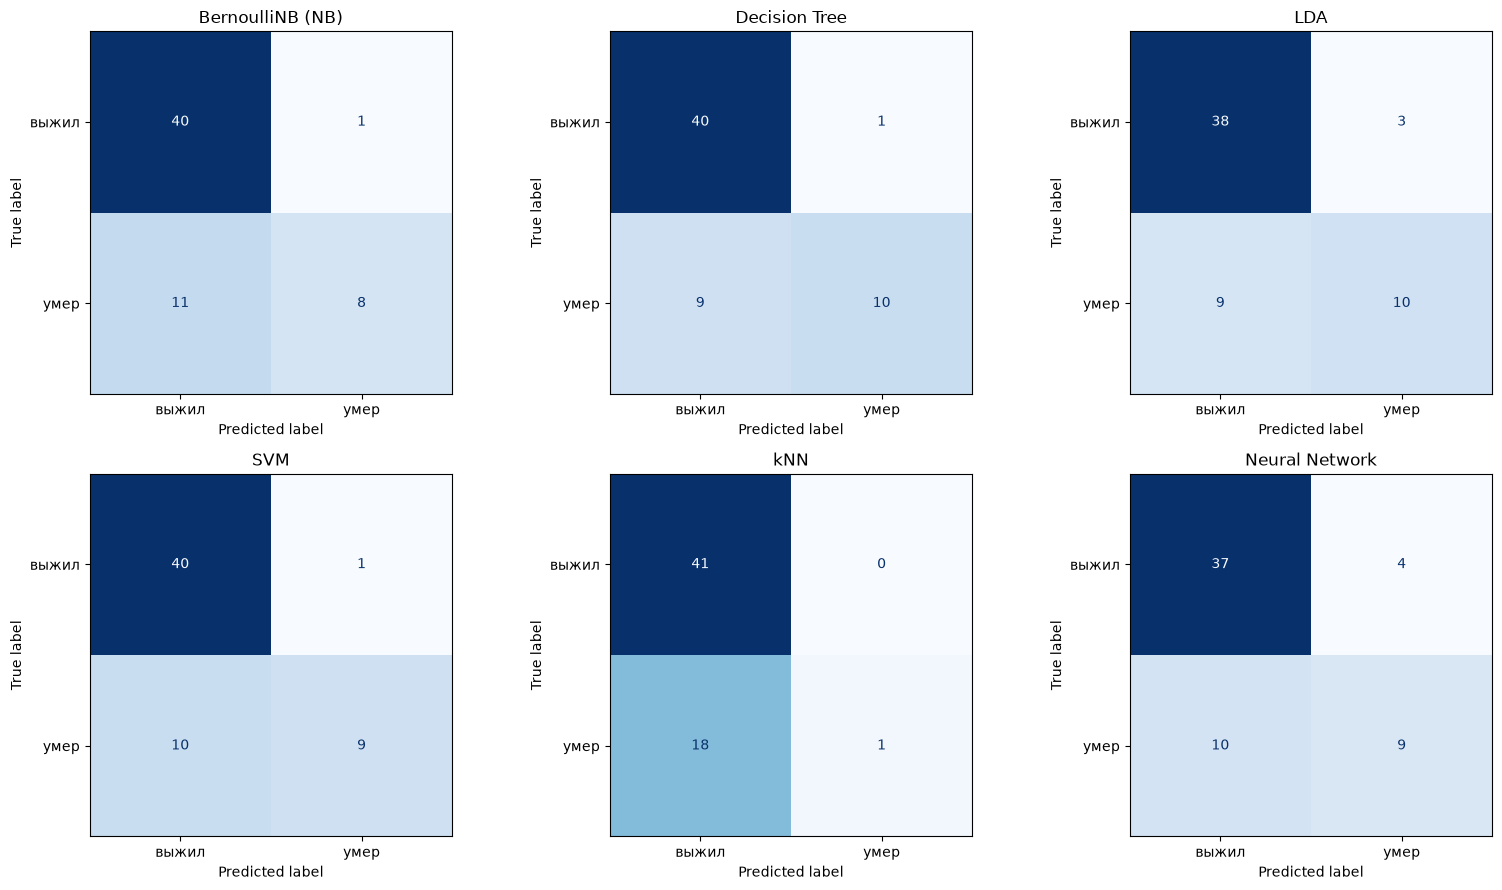

In [40]:
# ROC-кривые на тестовой выборке (для наивного Байеса — лучший вариант по CV)
roc_set = {f"{best_nb} (NB)": best_nb, "Decision Tree": "Decision Tree", "LDA": "LDA", "SVM": "SVM", "kNN": "kNN", "Neural Network": "Neural Network"}
plt.figure(figsize=(8, 7))
for lab, key in roc_set.items():
    fpr, tpr, _ = roc_curve(y_test, get_scores(models[key], X_test))
    plt.plot(fpr, tpr, lw=2, label=f"{lab} (AUC = {results[key]['roc_auc']:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC-кривые на тестовой выборке"); plt.legend(loc="lower right"); plt.show()

# матрицы ошибок
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (lab, key) in zip(axes.ravel(), roc_set.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, models[key].predict(X_test)), display_labels=["выжил", "умер"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(lab); ax.grid(False)
plt.tight_layout(); plt.show()

**Вывод.** ROC-кривые SVM, LDA и дерева решений лежат выше остальных (AUC 0.85–0.87); BernoulliNB и нейросеть — ниже (AUC 0.78–0.80), kNN — в середине. Ступенчатый вид кривых связан с малым размером теста. Матрицы ошибок показывают основную проблему всех моделей: пропуск умерших пациентов (FN: 9 у LDA и дерева, 10 у SVM и нейросети, 11 у BernoulliNB, 18 из 19 у kNN) при очень малом числе ложных тревог (FP: 1–4) — модели «осторожны» в отношении класса 1, что естественно при дисбалансе 68/32.

### Устойчивость сравнения
Тестовая выборка мала (60 пациентов, 19 из них — класс 1), поэтому разница в 1–2 процентных пункта может быть случайной. Для проверки оценим лучшие найденные модели ещё и **повторной стратифицированной кросс-валидацией на всём датасете** (5 блоков × 10 повторов, параметры берутся уже подобранные; оценка слегка оптимистична, так как параметры подбирались на 80 % этих же данных, но одинаково для всех методов). Нейросеть в эту проверку не включена из-за времени обучения.

In [41]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.base import clone
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
rows = {}
for n in classic:
    r = cross_validate(clone(models[n]), X, y, cv=rcv, scoring=METRICS, n_jobs=2)
    rows[n] = {**{NAMES[m]: r["test_" + m].mean() for m in METRICS}, "AUC std": r["test_roc_auc"].std()}
rep = pd.DataFrame(rows).T
display(rep.round(3).sort_values("AUC-ROC", ascending=False))

,Accuracy,Precision,Recall,F1-score,AUC-ROC,AUC std
LDA,0.830,0.774,0.673,0.715,0.875,0.045
SVM,0.802,0.778,0.539,0.630,0.873,0.044
BernoulliNB,0.824,0.827,0.580,0.676,0.867,0.054
Decision Tree,0.823,0.732,0.714,0.719,0.857,0.040
GaussianNB,0.735,0.778,0.243,0.363,0.855,0.054
kNN,0.717,0.933,0.124,0.214,0.847,0.046
ComplementNB,0.748,0.753,0.335,0.454,0.812,0.066
MultinomialNB,0.682,0.180,0.009,0.018,0.797,0.065


**Вывод.** По повторной кросс-валидации на всём датасете (50 разбиений) лидируют **LDA (AUC 0.875, F1 0.715, Recall 0.673)**, SVM (0.873) и BernoulliNB (0.867); дерево решений (0.857) уступает по AUC, но имеет самый высокий Recall (0.714) и F1 (0.719). Разброс AUC по разбиениям (std ≈ 0.045) больше различий между верхними методами, поэтому LDA, SVM, BernoulliNB и дерево статистически почти неразличимы по AUC; заметно хуже — ComplementNB и MultinomialNB (AUC 0.81 и 0.80), а GaussianNB и kNN, имея неплохой AUC (0.855 и 0.847), почти не находят умерших пациентов при пороге 0.5 (Recall 0.24 и 0.12).

## Заключение

В работе на датасете *Heart Failure Clinical Records* (299 пациентов, бинарная цель `DEATH_EVENT`) построены и сравнены классификаторы пяти семейств (наивный Байес — 4 варианта, дерево решений, LDA, SVM, kNN) и нейронная сеть на TensorFlow/Keras; для каждого метода исследовано влияние гиперпараметров и выполнен подбор через `GridSearchCV`, обучение сети отслеживалось в TensorBoard.

**Основные результаты.**
1. **Подготовка данных:** пропусков нет; данные несбалансированы (32 % класса «умер»), поэтому использована стратификация, а наряду с Accuracy оценивались Precision, Recall, F1 и AUC-ROC. Масштабирование встроено в `Pipeline`, что исключает утечку.
2. **Гиперпараметры оказывают сильное влияние:** у дерева — глубина и `min_samples_leaf` (CV AUC 0.754 → 0.886), у SVM — `C` и `gamma` (вырождение в мажоритарный класс при малых значениях и переобучение при больших), у kNN — число соседей и обязательная стандартизация (AUC 0.58 без неё и 0.81 с ней), у BernoulliNB — порог бинаризации; у LDA — слабое (устойчивый метод для малых выборок с примерно линейной границей), у нейросети — число эпох, размер батча, ёмкость сети и скорость обучения (недообучение при малых и переобучение при больших).
3. **Лучшие методы.** На тесте лучшим по AUC является SVM (0.868), по Accuracy/F1 — дерево решений (0.833 / 0.667). Более надёжная повторная кросс-валидация ставит на первое место **LDA** (AUC 0.875, F1 0.715), с практически равными SVM (0.873) и BernoulliNB (0.867). Нейросеть (AUC на тесте 0.80–0.81, CV AUC 0.867) не превзошла линейные модели — на выборке в несколько сотен объектов у неё нет преимущества, а настройка и воспроизводимость сложнее.
4. **Слабое место всех моделей — Recall класса «умер»** (0.5–0.7 при пороге 0.5, для kNN и наивных Байесов — ещё ниже), что для медицинской задачи критично: пропустить пациента из группы риска хуже, чем дать ложную тревогу. Его можно повысить без потери AUC — через `class_weight='balanced'`, априорные вероятности (`priors`) или снижение порога классификации.

**Итог.** Для данного датасета наиболее обоснованным выбором является **линейный дискриминантный анализ** (или линейный/rbf SVM с `class_weight='balanced'`): они дают наивысший или статистически не отличимый AUC (≈ 0.87), быстро обучаются, устойчивы и интерпретируемы. Дерево решений — хорошая альтернатива, если важна наглядность правил (корень: `time ≤ 73.5`) и Recall.

**Ограничения.** Небольшая выборка (тест — 60 объектов, из них 19 положительных) даёт шумные оценки, поэтому различия в 1–3 п.п. нельзя считать значимыми; признак `time` (срок наблюдения) недоступен в момент поступления пациента, и без него качество практически применимой модели, вероятно, будет ниже (это не проверялось).